# Predict Term Deposit Subscription from Bank Marketing Campaign Data
#### Machine Learning project - Davide De Santis

---

## Definizione del problema

Durante una campagna telefonica, **prima** che il prossimo contatto venga effettuato/programmato vogliamo individuare i clienti con maggiore propensione a sottoscrivere un deposito a termine.

Per ciascun cliente, la variabile target e' definita come
$$
    y =
    \begin{cases}
    1 & \text{se il cliente sottoscrive il deposito}\\
    0 & \text{altrimenti}
    \end{cases}
$$
Abbiamo quindi un *problema di classificazione binaria*.

Sia inoltre $x = (x_1, \dots, x_n)$ l'insieme delle informazioni considerate disponibili al momento della previsione. La previsione viene effettuata **prima che il successivo contatto venga programmato o effettuato**. 

La quantita' di interesse e' pertanto:
$$
    \mathbb{P}(y = 1 | x)
$$

Il modello addestrato produce per ogni cliente uno score
$$
    \hat{p}(x)
$$
che rappresenta la propensione del cliente a sottoscrivere il deposito. Infine, lo score viene trasformato in una decisione binaria attraverso una soglia decisionale $\tau$:
$$
    \hat y =
    \begin{cases}
    1 & \text{se } \hat p(x) \geq \tau\\
    0 & \text{altrimenti}
    \end{cases}
$$

---

## Dataset
Il Dataset utilizzato e' [UCI Bank Marketing dataset](https://www.kaggle.com/datasets/adityamhaske/bank-marketing-dataset) e contiene:
- 45,211 osservazioni
- 16 input features + target y
- Features numeriche e categoriche

Questa e' la lista completa delle features e dei loro significati:
1. **age**: eta' del cliente (Numeric)
2. **job**: tipo di lavoro del cliente (Categoric: admin, unknown, unemployed, management, housemaid, entrepreneur, student, blue-collar, self-employed, retired, technician, services)
3. **marital**: stato coniugale (Categoric: married, divorced(divorced or widowed), single)
4. **education**: livello di istruzione (Categoric: unknown, secondary, primary, tertiary)
5. **default**: ha credito in default? (Binary: yes, no)
6. **balance**: bilancio annuale medio, in euro (Numeric)
7. **housing**: ha un mutuo per la casa? (Binary: yes, no)
8. **loan**: ha un mutuo personale? (Binary: yes, no)
9. **contact**: metodo di comunicazione dell'ultimo contatto (Categorical: unknown, telephone, cellular)
10. **day**: giorno del mese dell'ultimo contatto (Numeric)
11. **month**: mese dell'anno dell'ultimo contatto (Categoric: jan, feb, ..., nov, dec)
12. **duration**: durata, in secondi, dell'ultimo contatto (Numeric)
13. **campaign**: numero di contatti effettuati durante questa campagna e per questo cliente (Numeric, include l'ultimo contatto)
14. **pdays**: numero di giorni passati da quando il cliente e' stato contattato l'ultima volta nella precedente campagna (Numeric, -1 significa che il cliente non e' stato precedentemente contattato)
15. **previous**: numero di contatti effettuati prima di questa campagna e per questo cliente (Numeric)
16. **poutcome**: risultato della precedente campagna (Categorical: unknown, other, failure, success)
17. **y**: il cliente ha sottoscritto il deposito? (Binary: yes, no)

Sotto le ipotesi adottate sul tempo di previsione, al cliente viene assegnato uno score di propensione alla sottoscrizione prima che il prossimo contatto venga effettuato o programmato. Pertanto le features che descrivono tale contatto (contact, day, month, duration) le assumiamo non disponibili.

Il dataset non contiene valori mancanti, alcune variabili categoriche contengono la categoria "unknown" ed e' stato deciso di trattarla come una categoria valida piuttosto che come valore mancante.

---
---

In [1]:
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Train/Val/Test
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, cross_val_predict)

# Preprocessing
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
#from sklearn.impute import SimpleImputer

# Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Feature Selection
from sklearn.feature_selection import SelectFromModel

# Feature Extraction
from sklearn.decomposition import PCA

# Metrics
from sklearn.metrics import(
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report, precision_recall_curve,
    roc_curve)


In [2]:
random_seed = 42
path = kagglehub.dataset_download("adityamhaske/bank-marketing-dataset")
filename = "bank-full.csv"
df = pd.read_csv(path + "/" + filename, sep=";")

In [3]:
print(f"Shape:{df.shape}")
df.head()


Shape:(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
print("=" * 50)
print("Missing values:")
print(df.isna().sum())

print("=" * 50)
print("Numer of duplicated rows: ", df.duplicated().sum())

Missing values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
Numer of duplicated rows:  0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


## Train/Test split

Il dataset e' diviso in training set ($80\%$) e test set ($20\%$) utilizzando la stratificazione rispetto al target per preservarne la distribuzione. La comparazione dei modelli, il tuning degli iperparametri e il tuning della soglia vengono effettuati sul training set utilizzando una 5-fold stratified cross-validation. Il test set non viene utilizzato per selezionare i modelli, ottimizzare gli iperparametri o determinare la soglia decisionale.

---
---

In [6]:
# Train/Test split

df["y"] = df["y"].astype(str).map({"yes":1, "no":0, "1":1, "0":0}).astype(int)
#df["y"] = df["y"].replace({"yes": 1, "no": 0}).astype(int)

train_df, test_df = train_test_split(df, test_size = 0.20, stratify = df["y"], random_state = random_seed)
print("=" * 20 + " Train" + "=" * 20)
print("Shape: ", train_df.shape)
print(train_df["y"].value_counts(normalize = True))

print("=" * 20 + " Test" + "=" * 20)
print("Shape: ", test_df.shape)
print(test_df["y"].value_counts(normalize = True))

==================== Train====================
Shape:  (36168, 17)
y
0    0.883018
1    0.116982
Name: proportion, dtype: float64
==================== Test====================
Shape:  (9043, 17)
y
0    0.883003
1    0.116997
Name: proportion, dtype: float64


In [7]:
train_df.describe()

,age,balance,day,duration,campaign,pdays,previous,y
count,36168.000000,36168.00000,36168.000000,36168.000000,36168.000000,36168.000000,36168.000000,36168.000000
mean,40.892999,1365.49342,15.817961,258.506940,2.763935,40.157238,0.581730,0.116982
std,10.627075,3068.54350,8.331980,259.142445,3.104161,100.162614,2.408766,0.321403
min,18.000000,-8019.00000,1.000000,0.000000,1.000000,-1.000000,0.000000,0.000000
25%,33.000000,74.00000,8.000000,103.000000,1.000000,-1.000000,0.000000,0.000000
50%,39.000000,451.00000,16.000000,180.000000,2.000000,-1.000000,0.000000,0.000000
75%,48.000000,1430.25000,21.000000,318.000000,3.000000,-1.000000,0.000000,0.000000
max,95.000000,102127.00000,31.000000,4918.000000,63.000000,871.000000,275.000000,1.000000


In [8]:
train_df.describe(include = "object")

,job,marital,education,default,housing,loan,contact,month,poutcome
count,36168,36168,36168,36168,36168,36168,36168,36168,36168
unique,12,3,4,2,2,2,3,12,4
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown
freq,7830,21771,18561,35521,20182,30355,23465,11062,29589


## Class Imbalance and Evaluation Metric

Dall'analisi della distribuzione del target risulta che solo $11\%$ sono positivi, ovvero sottoscrivono. Questo evidenzia un forte sbilanciamento delle classi, pertanto bisogna scegliere con attenzione le metriche utilizzate per valutare il modello. Infatti il forte sbilanciamento del target rende una metrica come l'**Accuracy** non abbastanza informativa come metrica primaria, in quanto anche il classificatore piu' banale, quello che restituisce sempre negativo, ottiene un'accuracy del $88.3\%$ non avendo pero' alcuna capacita predittiva.

Pertanto la scelta della metrica principale per la valutazione del modello e' ricaduta sulla **Average Precision (AP)** che rappresenta il compromesso tra **Precision** e **Recall** su varie soglie di classificazione e concentra la valutazione sulla capacita' del modello di assegnare score elevati agli esempi positivi e pertanto di ordinarli correttametne.

---
---

Text(0.5, 1.0, 'Target distribution')

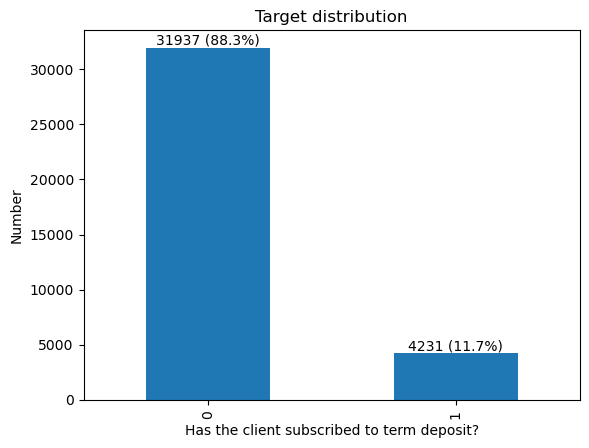

In [9]:
# Plot distribuzione di sottoscrizioni

counts = train_df["y"].value_counts()
perc = train_df["y"].value_counts(normalize = True) * 100
ax = counts.plot(kind = "bar")
for i,value in enumerate(counts):
    ax.text(i, value, f"{value} ({perc.iloc[i]:.1f}%)", ha="center", va="bottom")
plt.xlabel("Has the client subscribed to term deposit?")
plt.ylabel("Number")
#plt.xticks(rotation = 0)
plt.title("Target distribution")




## Exploratory Data Analysis

L'analisi esplorativa dei dati e' effettuata **esclusivamente sul training set**, cosi che il test set non venga visto durante lo sviluppo del modello.

Lo scopo di questa analisi e' di identificare potenziali pattern informativi e variabili fortemente asimmetriche, nonche analizzare le features che non sono disponibili al momento della predizione.



In [10]:
# Separo features numeriche da quelle categoriche
num_df = train_df.select_dtypes(include = "int64")
cat_df = train_df.select_dtypes(include = "object")

print("=" * 50)
num_df.info()
print("=" * 50)
cat_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 36168 entries, 24001 to 44229
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   age       36168 non-null  int64
 1   balance   36168 non-null  int64
 2   day       36168 non-null  int64
 3   duration  36168 non-null  int64
 4   campaign  36168 non-null  int64
 5   pdays     36168 non-null  int64
 6   previous  36168 non-null  int64
 7   y         36168 non-null  int64
dtypes: int64(8)
memory usage: 2.5 MB
<class 'pandas.core.frame.DataFrame'>
Index: 36168 entries, 24001 to 44229
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   job        36168 non-null  object
 1   marital    36168 non-null  object
 2   education  36168 non-null  object
 3   default    36168 non-null  object
 4   housing    36168 non-null  object
 5   loan       36168 non-null  object
 6   contact    36168 non-null  object
 7   month      36168 non-n

### Correlation between numeric features and target

Esaminiamo innanzitutto la correlazione lineare tra le features numeriche e il target.
Tra le variabili numeriche, **duration**, **pdays**, **previous** e **balance** mostrano la maggior correlazione lineare positiva con il target, mentre **campaign** mostra la maggior correlazione lineare negativa con il target.


Text(0.5, 1.0, 'Correlation with target')

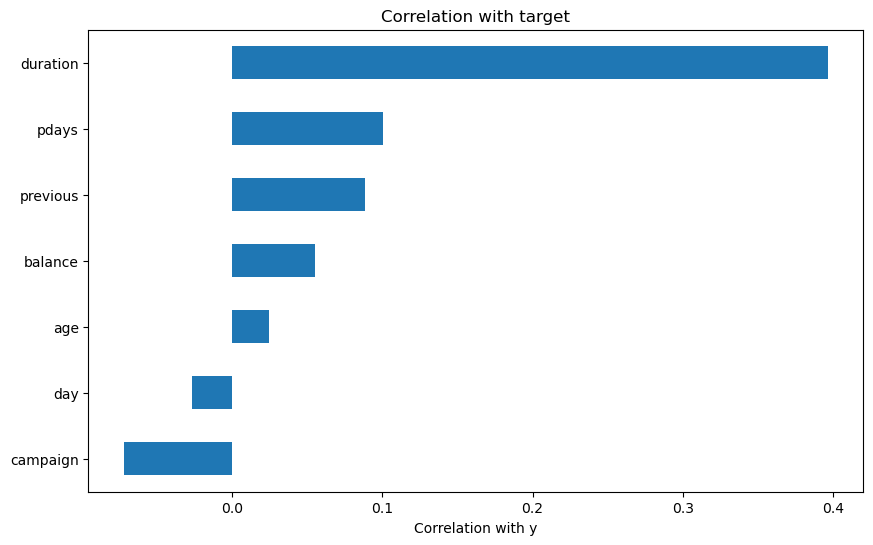

In [11]:
# Correlazione tra features numeriche e target
corr_vec = num_df.corr()["y"].drop("y")
plt.figure(figsize = (10,6))
corr_vec.sort_values().plot(kind = "barh")
plt.xlabel("Correlation with y")
plt.title("Correlation with target")


### Age

Le distribuzioni delle eta' dei clienti che sottoscrivono il deposito si sovrappone con quella dei clienti che non lo sottoscrivono. L'eta media e' di circa $40.8$ anni tra chi non sottoscrive e di circa $41.6$ tra chi sottoscrive. Sembra percio' che la sola eta' dia informazioni predittive limitate. 


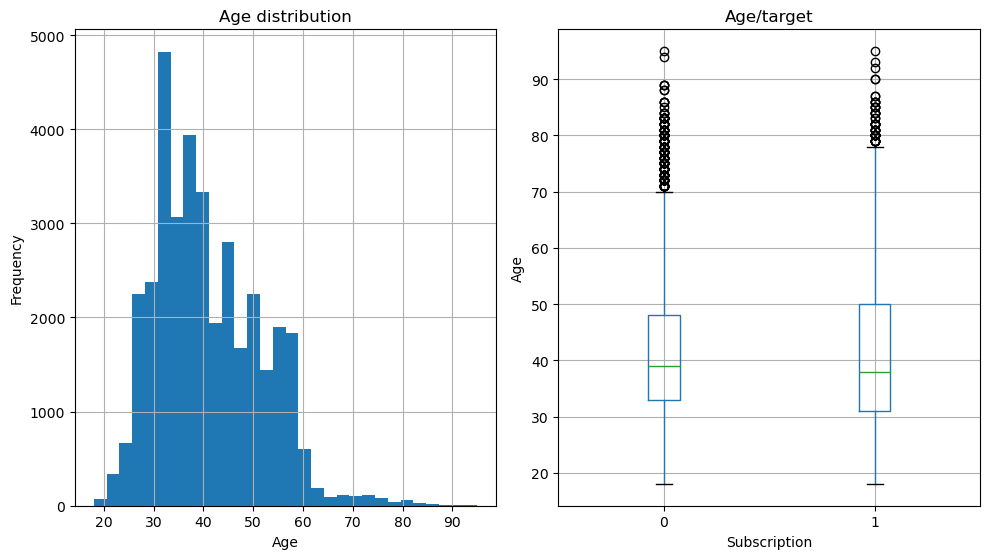

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
0,31937.0,40.797445,10.175616,18.0,33.0,39.0,48.0,95.0
1,4231.0,41.614276,13.537990,18.0,31.0,38.0,50.0,95.0


In [12]:
# Age feature
fig, axes = plt.subplots(1,2, figsize = (10,6))
train_df["age"].hist(bins = 30, ax = axes[0])
axes[0].set_title("Age distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Frequency")

train_df.boxplot(column = "age", by = "y", ax = axes[1])
axes[1].set_title("Age/target")
axes[1].set_xlabel("Subscription")
axes[1].set_ylabel("Age")

plt.tight_layout()
plt.suptitle("")
plt.show()

train_df.groupby("y")["age"].describe()

---

### Balance

La feature **balance** presenta una distribuzione fortemente asimmetrica verso destra e contiene sia valori negativi che grandi outliers positivi. 

Chi sottoscrive tende ad avere un balance piu alto: la mediana e' circa $740$ euro, contro i $419$ euro di chi non sottoscrive. Nonostante questo le distribuzioni tendono a sovrapporsi, percio' questa features da sola non sembra essere sufficiente a separare le due classi.

Alla feature balance, poiche' puo' assumere valori negativi, non verra applicata una trasformazione logaritmica standard, ma viene mantenuta la sua rappresentazione originale. Un possibile approccio futuro potrebbe essere cercare una trasformazione adatta a questa features, in modo tale da aiutare i modelli lineari, e vedere se le performance migliorano.

---

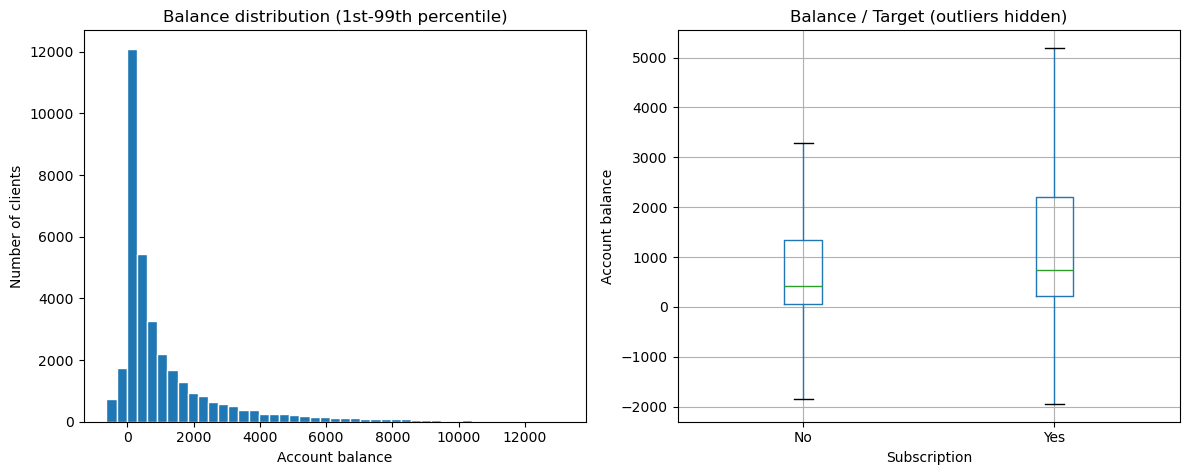

Note: trimming/hidden outliers affect only these plots, not model input.


,count,median,mean
y,,,
0,31937,419.0,1304.0
1,4231,740.0,1829.4


In [13]:
# Balance feature

q01, q99 = train_df["balance"].quantile([0.01, 0.99])
central_balance = train_df.loc[train_df["balance"].between(q01, q99), "balance"]

fig, axes = plt.subplots(1, 2, figsize = (12, 5))
axes[0].hist(central_balance, bins = 45, edgecolor = "white")
axes[0].set_title("Balance distribution (1st-99th percentile)")
axes[0].set_xlabel("Account balance")
axes[0].set_ylabel("Number of clients")

train_df.boxplot(column = "balance", by = "y", showfliers = False, ax = axes[1])
axes[1].set_title("Balance / Target (outliers hidden)")
axes[1].set_xlabel("Subscription")
axes[1].set_xticklabels(["No", "Yes"])
axes[1].set_ylabel("Account balance")

fig.suptitle("")
fig.tight_layout()
plt.show()

print("Note: trimming/hidden outliers affect only these plots, not model input.")
display(train_df.groupby("y")["balance"].agg(["count", "median", "mean"]).round(1))

### Campaign

La feature **campaign** presenta una distribuzione fortemente asimettrica verso destra: la maggior parte delle osservazioni corrispondono a un pochi contatti, mentre solo un numero limitato di clienti ha ricevuto molti contatti ripetuti.

Il tasso di sottoscrizione sembra diminuire quando il numero di contatti aumenta, ma questo non va interpretato come un rapporto di causa-effetto. Inoltre il tasso di sottoscrizione per numeri di contatti grandi va interpretato con cautela in quanto presentano un campione piccolo.

Un altro problema con la variabile campaign e' il fatto che contiene il contatto corrente, mentre sotto le nostre ipotesi tale contatto non e' ancora avvenuto/pianificato. Pertanto l'informazione disponibile al momento della predizione e' 

$$
\text{prior\_campaign} = \text{campaign} - 1
$$ 

Siccome la distribuzione e' fortemente asimmetrica verso destra, e poiche' assume solo valori positivi, possiamo applicare una trasformazione di tipo logaritmico 

$$
\text{log\_campaign} = \log(1+\text{prior\_campaign}) = \log(\text{campaign})
$$

Tale trasformazione sara usata piu' avanti.

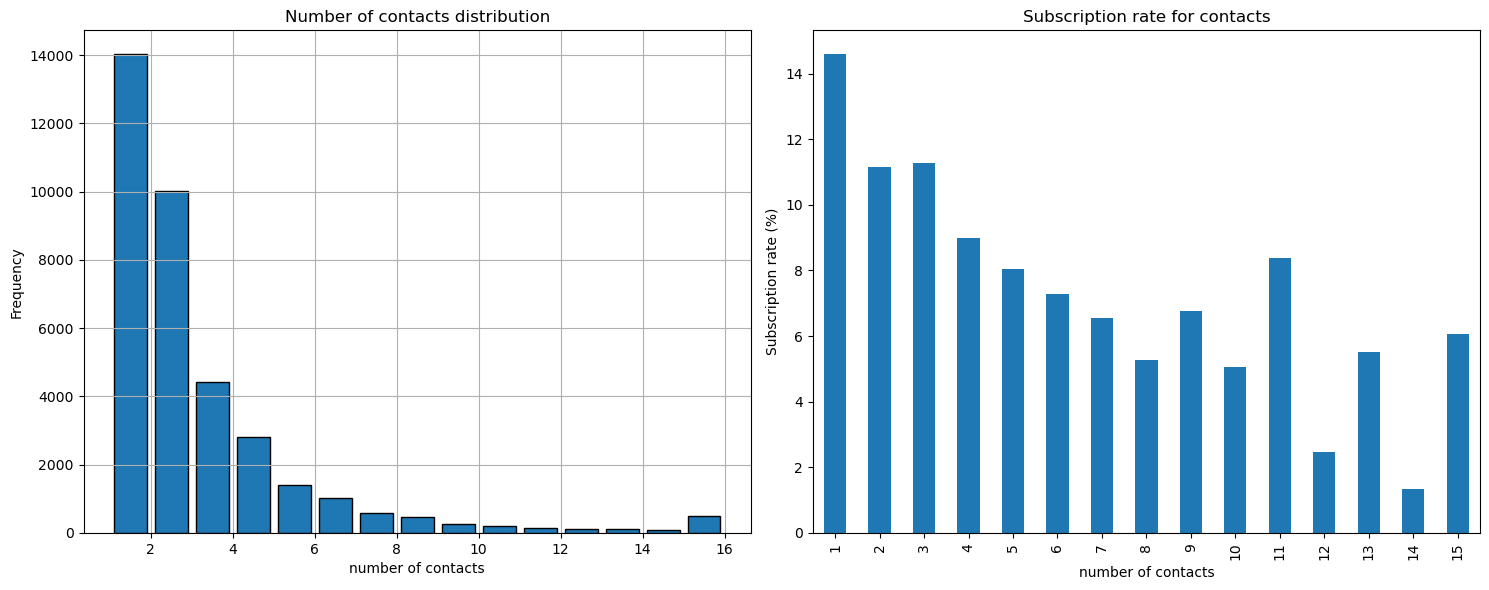

,mean,count
campaign,,
1,0.145872,14026
2,0.111543,10023
3,0.112647,4412
4,0.089840,2805
5,0.080338,1419
6,0.072692,1018
7,0.065436,596
8,0.052632,456
9,0.067729,251


In [14]:
# Campaign feature

# tasso di sottoscrizione per numero di contatti
campaign_rate = (train_df.groupby("campaign")["y"].agg(["mean", "count"]))

fig, axes = plt.subplots(1,2, figsize = (15,6))
#train_df["campaign"].clip(upper = 15).plot(kind = "bar", ax =axes[0])
train_df["campaign"].clip(upper = 15).hist(bins = range(1,17), ax = axes[0], rwidth = 0.8, edgecolor = "black")
axes[0].set_title("Number of contacts distribution")
axes[0].set_xlabel("number of contacts")
axes[0].set_ylabel("Frequency")



(campaign_rate.loc[1:15, "mean"]*100).plot(kind = "bar", ax = axes[1])
axes[1].set_title("Subscription rate for contacts")
axes[1].set_xlabel("number of contacts")
axes[1].set_ylabel("Subscription rate (%)")

plt.tight_layout()
plt.show()
#train_df["campaign"].describe()
#train_df.groupby("y")["campaign"].describe()

display(campaign_rate.loc[1:15])


### Pdays

La feature **pdays** richiede particolare attenzione, in quanto il valore $-1$ non rappresenta il numero reale di giorni, bensi' ha un significato specifico: indica che il cliente non e' mai stato contattato nelle precedenti campagne.

Tale distinzione sembra essere informativa: nel training il tasso di sottoscrizione e' approssimativamente:

$$
\mathbb{P}(y = 1 \mid \text{non precedentemente contattato}) \approx 9.2\%
$$

mentre

$$
\mathbb{P}(y = 1 \mid \text{precedentemente contattato}) \approx 22.8\%
$$

pertanto, in aggiunta all'informazione originale, introduciamo una feature binaria

$$
\text{prev\_cont} = \mathbf{1}(\text{pdays} \neq -1)
$$

che rappresenta esplicitamente se il cliente e' stato contattato in passato.

In [15]:
# pdays feature: number of days that passed by after the client was last contacted 
# from a previous campaign (-1 = not previosly contacted)

#(train_df["pdays"] == -1).mean()
tmp = train_df.copy()
tmp["prev_cont"] = np.where(tmp["pdays"] == -1, "No", "Yes")
pd.crosstab(tmp["prev_cont"], tmp["y"], normalize="index")


y,0,1
prev_cont,,
No,0.907822,0.092178
Yes,0.771567,0.228433


### Previous

La feature **previous** e' anch'essa fortemente asimmetrica verso destra e concentrata in zero. La maggior parte dei clienti non hanno contatti precedenti e solo una piccola parte ha avuto molti contatti.

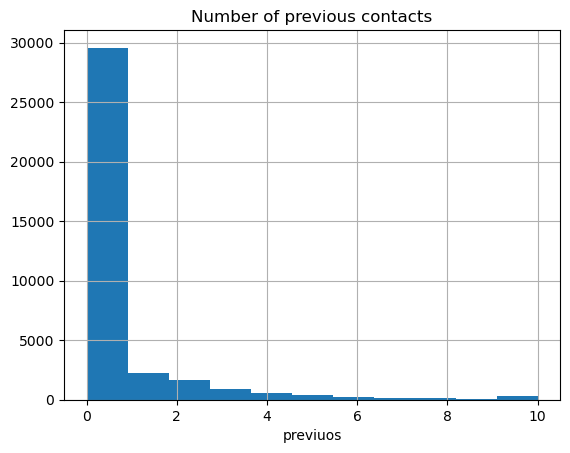

count    36168.000000
mean         0.581730
std          2.408766
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        275.000000
Name: previous, dtype: float64

In [16]:
# previous feature: number of contacts performed before this campaign and for this client
train_df["previous"].clip(upper = 10).hist(bins = 11)
plt.title("Number of previous contacts")
plt.xlabel("previuos")
plt.show()
train_df["previous"].describe()

In [17]:
def cat_summary(df, feature, target = "y"):
    summary = (df.groupby(feature, observed=False)[target]
        .agg(support = "size", subscription_rate = "mean")
        .sort_values("subscription_rate", ascending = False)
    )
    summary["subscription_rate_pct"] = 100 * summary["subscription_rate"]
    return summary
"""
def plot_cat_feat(df, feature, target = "y"):
    summary = cat_summary(df = df, feature = feature, target = target)
    order = summary.index
    fig, axes = plt.subplots(1, 2, figsize = (14, 5))

    summary.loc[order, "support"].plot(kind = "bar", ax = axes[0])
    axes[0].set_title(f"Number of observations by {feature}")
    axes[0].set_xlabel(feature)
    axes[0].set_ylabel("Count")
    axes[0].tick_params(axis = "x", rotation = 45)

    summary.loc[order, "subscription_rate_pct"].plot(kind = "bar", ax = axes[1])
    axes[1].set_title(f"Subscription rate by {feature}")
    axes[1].set_xlabel(feature)
    axes[1].set_ylabel("Subscription rate (%)")
    axes[1].tick_params(axis = "x", rotation = 45)

    plt.tight_layout()
    plt.show()
    return summary
"""

def plot_cat_feat(df, feature, target = "y"):
    summary = cat_summary(df, feature, target)
    plot_data = summary.iloc[::-1]
    baseline_pct = 100 * df[target].mean()

    fig_height = max(3.2, 0.4 * len(plot_data) + 1.3)
    fig, ax = plt.subplots(figsize = (9.5, fig_height))
    ax.barh(plot_data.index.astype(str), plot_data["subscription_rate_pct"])
    ax.axvline(baseline_pct, linestyle = "--", color = "gray", linewidth =1.3,
        label = f"Overall subscription rate: {baseline_pct:.1f}%")

    max_rate = max(float(plot_data["subscription_rate_pct"].max()), baseline_pct)
    ax.set_xlim(0, max_rate * 1.48 + 0.5)
    for row, (_, record) in enumerate(plot_data.iterrows()):
        ax.text(record["subscription_rate_pct"] + max_rate * 0.02, row,
            f'{record["subscription_rate_pct"]:.1f}% (n={int(record["support"]):,})',
            va = "center", fontsize = 9)

    ax.set(title = f"Subscription rate by {feature}", xlabel = "Subscription rate (%)")
    ax.legend(loc = "lower right", fontsize = 9)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()
    return summary



### Job and Education

Il tasso di sottoscrizione varia attraverso la tipologia di occupazione e il livello di formazione.

---

Per quanto riguarda la feature **job**, studenti e pensionati mostrano il piu alto tasso di sottoscrizione ($\approx 28.8\%$ e $22.9\%$ rispettivamente), mentre i blue-collar (operai, manovali), housemaid e imprenditori mostrano tassi minori.

---

Per **education**, i clienti con istruzione terziaria mostrano un tasso di sottoscrizione piu' elevato ($\approx 14.9\%$) rispetto ai clienti con istruzione primaria ($\approx 8.6\%$)

Tali differenze suggeriscono che il profilo del cliente possa contenere informazione predittiva.
Chiaramente, tali tassi di sottoscrizione vanno interpretati anche in base alla dimensione del campione, in quanto stime basate su categorie rare e quindi su campioni piu' piccoli sono meno stabili.

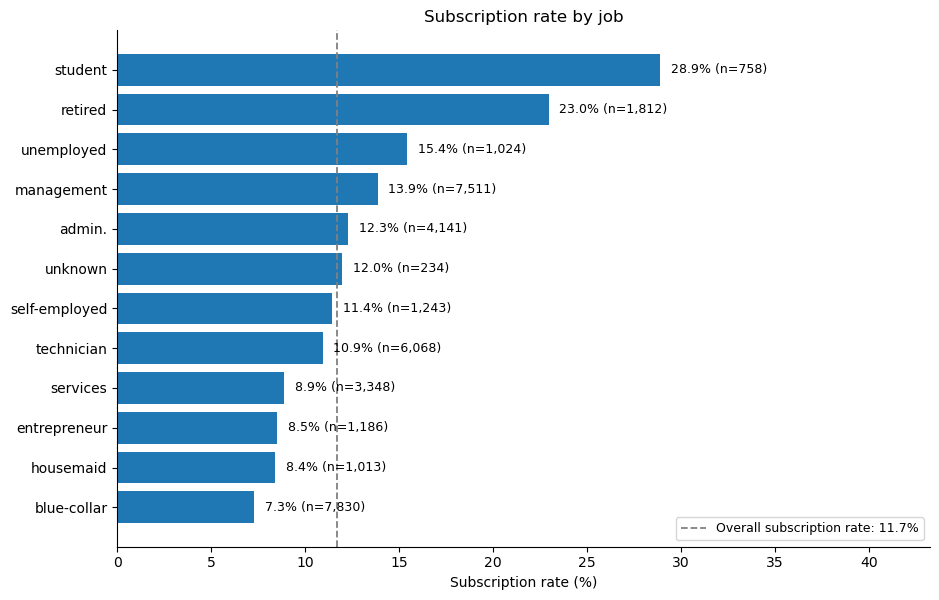

,support,subscription_rate,subscription_rate_pct
job,,,
student,758,0.288918,28.891821
retired,1812,0.229581,22.958057
unemployed,1024,0.154297,15.429688
management,7511,0.138597,13.859672
admin.,4141,0.122917,12.291717
unknown,234,0.119658,11.965812
self-employed,1243,0.114240,11.423974
technician,6068,0.109262,10.926170
services,3348,0.089008,8.900836


In [18]:
# job feature: type of job

job_summary = plot_cat_feat(train_df, "job")
display(job_summary)


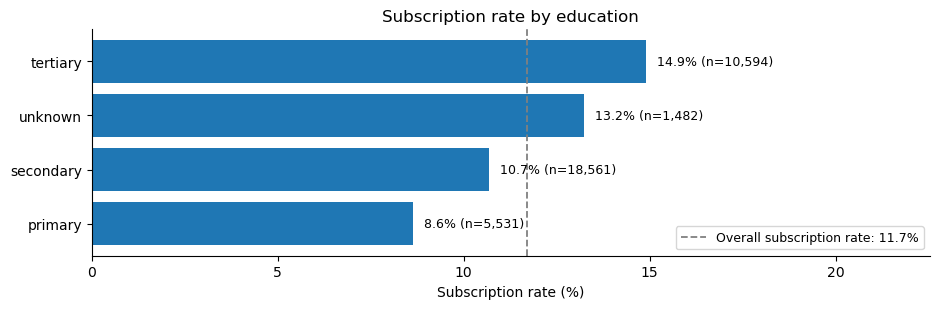

,support,subscription_rate,subscription_rate_pct
education,,,
tertiary,10594,0.148858,14.885784
unknown,1482,0.132254,13.225371
secondary,18561,0.106729,10.672916
primary,5531,0.086241,8.624119


In [19]:
# education feature: 

education_summary = plot_cat_feat(train_df, "education")
display(education_summary)


### Housing and loan

I clienti con all'attivo un mutuo per una casa o un mutuo personale mostrano un minore tasso di sottoscrizione rispetto ai clienti senza mutui. Pertanto anche queste features sembrano contenere dell'informazione potenzialmente predittiva.

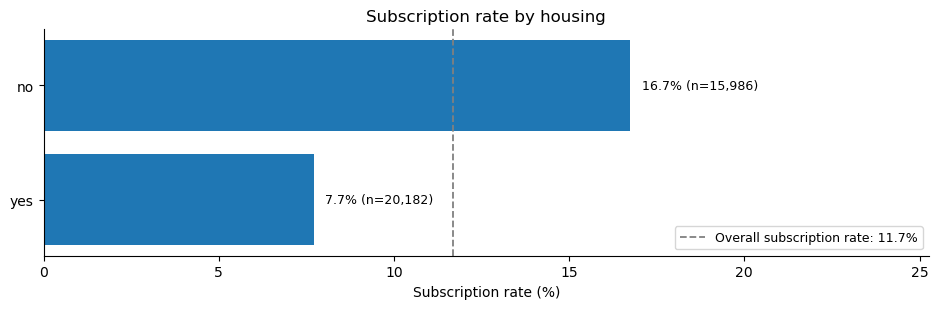

,support,subscription_rate,subscription_rate_pct
housing,,,
no,15986,0.167334,16.733392
yes,20182,0.077098,7.709840


In [20]:
# Housing feature: has housing loan?

housing_summary = plot_cat_feat(train_df, "housing")
display(housing_summary)


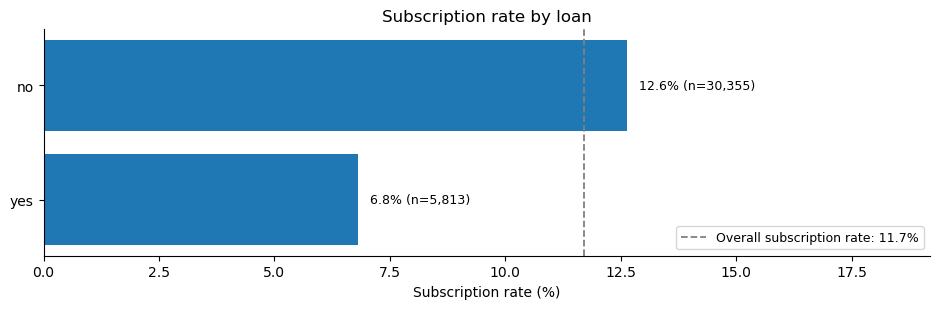

,support,subscription_rate,subscription_rate_pct
loan,,,
no,30355,0.126338,12.633833
yes,5813,0.068123,6.812317


In [21]:
# Loan feature: has personal loan?

loan_summary = plot_cat_feat(train_df, "loan")
display(loan_summary)


### Poutcome

La feature **poutcome** mostra una delle piu' chiare associazioni con il target. I clienti che nelle precedenti campagne hanno sottoscritto il deposito hanno un tasso di sottoscrizione significativamente maggiore rispetto ai clienti con outcome failure, other e unknown.

Cio' supporta l'ipotesi che lo storico delle campagne precedenti contenga informazioni utili al fine della predizione sulla campagna attuale. 

Ancora una volta pero', non bisogna interpretare questa associazione come un rapporto di causa effetto.

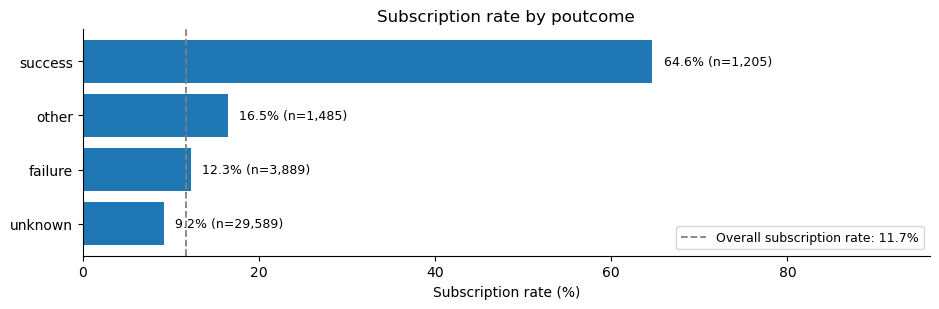

,support,subscription_rate,subscription_rate_pct
poutcome,,,
success,1205,0.646473,64.647303
other,1485,0.164983,16.498316
failure,3889,0.122911,12.291077
unknown,29589,0.092230,9.223022


In [22]:
# poutcome feature: outcome of the previous marketing campaign

poutcome_summary = plot_cat_feat(train_df, "poutcome")
display(poutcome_summary)

### Analisi delle features non disponibili al momento della predizione

Nonostante le features **month** e **duration** verranno successivamente escluse nella creazione del modello, ai fini descrittivi e di confronto ne analizziamo comunque le caratteristiche.

Per cio' che riguarda la feature **month**, si osserva che il tasso di sottoscrizione varia significativamente durante i mesi, suggerendo che il periodo in cui il contatto viene effettuato sia associato con il risultato.

Come gia' detto pero' questa informazione non e' disponibile al momento della previsione, pertanto non verra' utilizzata nel modello finale.

---

La feature **duration** mostra invece la piu' forte relazione con il target tra tutte le features numeriche. Le chiamate associate alle sottoscrizione del deposito, in media, durano significativamente di piu delle chiamate in cui il cliente non sottoscrive.

Pero' questa informazione e' disponibile solo dopo che il contatto con il cliente e' avvenuto e pertanto non puo' essere utilizzata nel nostro modello.

Piu' avanti viene effettuato un esperimento che mostra come l'utilizzo di tale feature posso aumentare in modo sostanzioso le performance predittive.

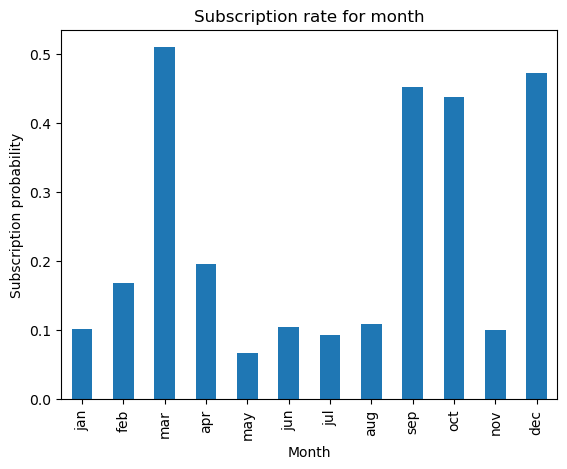

In [23]:
# Month feature: last contact month of year
train_df["month"].describe()
order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_rate = (train_df.groupby("month")["y"].mean().reindex(order))
month_rate.plot(kind = "bar")
plt.title("Subscription rate for month")
plt.xlabel("Month")
plt.ylabel("Subscription probability")
plt.show()

Text(0, 0.5, 'Duration (s)')

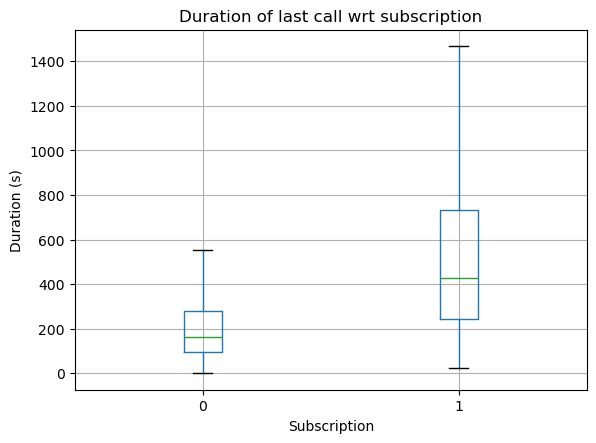

In [24]:
# Duration feature: last contact duration, in seconds

train_df.groupby("y")["duration"].describe()
train_df.boxplot(column="duration", by="y", showfliers = False)
plt.title("Duration of last call wrt subscription")
plt.suptitle("")
plt.xlabel("Subscription")
plt.ylabel("Duration (s)")

### Conclusioni

La EDA suggerisce che nessuna singola feature del cliente sia sufficiente a separare correttamente le due classi. Nonostante cio' si evidenziano dei pattern utili.

Le feature legate al profilo del cliente come **balance**, **job**, **education**, **housing** e **loan** mostrano differenze nei tassi di sottoscrizioni. Le features legate alle campagna precedenti, come **pdays**, **previous** e in particolare **poutcome** appaiono particolarmente informative.

La EDA ha permesso inoltre di identificare due importanti caratteristiche di cui bisognera' tener conto al momento della feature engineering. La feature **campaign** che e' fortemente asimmetrica verso destra e nella sua definizione originale contiente il contatto corrente, e il valore speciale $-1$ della feature "pdays"

Infine, le feature che descrivono il contatto corrente, in particolare **duration**, possono contenere molta informazione predittiva, ma saranno escluse in quanto non disponibili sotto le ipotesi adottate in questo progetto.

---
---



## Feature Engineering

- Le features contact, day, month e duration abbiamo supposto non essere disponibili al momento della previsione, pertanto andranno eliminate.
- La feature campaign rappresenta il numero di contatti effettuati in questa campagna con un cliente, incluso l'ultimo che secondo le nostre assunzioni non e' ancora stato effettuato, pertanto dobbiamo considerare previous_campaign = campaign - 1. A causa della forte coda verso destra della feature, si e' deciso di riscalarla prendendone log(p_campaign + 1) = log(campaign) percio' introduciamo la nuova featrures "log_campaign"
- La feature pdays ha un valore "speciale" ($-1$) che rappresenta un cliente che non e' mai stato contattato precedentemente. Pertanto si e' deciso di aggiungere una nuova feature prev_cont che rappresenta proprio cio.

Tutte queste modifiche sono state applicate sia sul training che sul test set.

---
---


In [25]:
# Feature Engineering

unavailable_feature = ["contact", "day", "month", "duration"]

#TRAIN

X_train = train_df.drop(columns = unavailable_feature + ["y"]).copy()
X_train["prev_cont"] = (X_train["pdays"] != -1).astype(int)
X_train["log_campaign"] = np.log(X_train["campaign"])
X_train = X_train.drop(columns = "campaign")
y_train = train_df["y"].copy()

#TEST
X_test = test_df.drop(columns = unavailable_feature + ["y"]).copy()
X_test["prev_cont"] = (X_test["pdays"] != -1).astype(int)
X_test["log_campaign"] = np.log(X_test["campaign"])
X_test = X_test.drop(columns = "campaign")
y_test = test_df["y"].copy()

X_train.info()



<class 'pandas.core.frame.DataFrame'>
Index: 36168 entries, 24001 to 44229
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   age           36168 non-null  int64  
 1   job           36168 non-null  object 
 2   marital       36168 non-null  object 
 3   education     36168 non-null  object 
 4   default       36168 non-null  object 
 5   balance       36168 non-null  int64  
 6   housing       36168 non-null  object 
 7   loan          36168 non-null  object 
 8   pdays         36168 non-null  int64  
 9   previous      36168 non-null  int64  
 10  poutcome      36168 non-null  object 
 11  prev_cont     36168 non-null  int64  
 12  log_campaign  36168 non-null  float64
dtypes: float64(1), int64(5), object(7)
memory usage: 3.9+ MB


## Preprocessing

La trasformazione dei dati scelta e' la seguente:
- Divisione delle feature in numeriche e categoriche
- Features numeriche -> Standard scaling
- Features categoriche -> One-hot encoding

Il tutto viene effettuato con delle pipeline e ColumnTransormer in modo tale che le trasformazioni avvengano in modo indipendente nei vari fold.

---
---

In [26]:
# Preprocessing

num_feat = ["age", "balance", "pdays", "previous", "prev_cont", "log_campaign"]
cat_feat = ["job", "marital", "education", "default", "housing", "loan", "poutcome"]


num_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("oneHotEnc", OneHotEncoder(handle_unknown = "ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_feat),
    ("cat", cat_pipeline, cat_feat)
])

#preprocessor.fit(X_train)
#feature_names = preprocessor.get_feature_names_out()
#print(feature_names)

## Models and Cross Validation

Per iniziare si sono scelte $4$ famiglie di modelli, con due configurazioni della regressione logistica, e una baseline di confronto

- [Baseline](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html): come baseline si e' scelto un **DummyClassifier** con strategy = "prior", ovvero un classificatore che predice sempre la classe con probabilita' a priori maggiore, nel nostro caso "No"

- [Regressione logistica](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html): Iperparametri(C, class_weight) con regolarizzazione $L^2$ 

- [Albero decisionale](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html): Iperparametri(max_depth) con misura di impurita' Gini.

- [Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html): Iperparametri(n_estimators) con criterio Gini

- [SVM](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html): Linear SVC, Iperparametri(C) con squared_hinge loss e regolarizzazione $L^2$

Viene effettuata una Cross validation a $5$ fold stratificati, da cui vengono scelti i tre modelli piu promettenti su cui fare il tuning degli iperparametri


I tre modelli che performano meglio rispetto alla metrica AP sono:
1. Logistic Regression (C = 1, class_weight = None): $\text{AP} \approx  0.3550$
2. Linear SVC (C = 1): $\text{AP} \approx  0.3511$
3. Random Forest (n_estimators = 200): $\text{AP} \approx  0.3219$

Nel prossimo step faremo il tuning degli iperparametri su questi tre modelli

---
---

In [27]:
# Cross validation

cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = random_seed
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

def cv_results(name, scores):
    return {
        "Model": name, 
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "Average Precision": scores["test_average_precision"].mean(),
        "AP std": scores["test_average_precision"].std()
    }

results = []

In [28]:
# Baseline

baseline_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DummyClassifier(strategy="prior"))
]) 

baseline_scores = cross_validate(baseline_pipeline, X_train, y_train,
    cv = cv, scoring = scoring, n_jobs = -1)

results.append(cv_results("Baseline", baseline_scores))




In [29]:
# Logistic Regression

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter = 2000, random_state = random_seed))
])

logistics_scores = cross_validate(logistic_pipeline, X_train, y_train,
    cv = cv, scoring = scoring, n_jobs = -1)

results.append(cv_results("Logistic Regression", logistics_scores))

In [30]:
#Logistic Regression Balanced

logistic_bal_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter = 2000, random_state = random_seed, class_weight = "balanced"))
])

logistics_bal_scores = cross_validate(logistic_bal_pipeline, X_train, y_train,
    cv = cv, scoring = scoring, n_jobs = -1)

results.append(cv_results("Logistic Regression Balanced", logistics_bal_scores))

In [31]:
# Decision Tree

tree_pipeline =Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(max_depth = 5, random_state = random_seed))
     
])

tree_scores = cross_validate(tree_pipeline, X_train, y_train,
    cv = cv, scoring = scoring, n_jobs = -1)

results.append(cv_results("Decision Tree", tree_scores))

In [32]:
# Random Forest

randFor_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators = 200, random_state = random_seed, n_jobs = -1))
])

randFor_scores = cross_validate(randFor_pipeline, X_train, y_train,
    cv = cv, scoring = scoring, n_jobs = -1)

results.append(cv_results("Random Forest", randFor_scores))

In [33]:
# SVM - linear svc

svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearSVC(random_state = random_seed))
])

svm_scores = cross_validate(svm_pipeline, X_train, y_train,
    cv = cv, scoring = scoring, n_jobs = -1)

results.append(cv_results("Linear SVC", svm_scores))

In [34]:
print("MODEL RESULTS")
results_df = pd.DataFrame(results)
results_df.head(10)

MODEL RESULTS


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,AP std
0,Baseline,0.883018,0.000000,0.000000,0.000000,0.500000,0.116982,0.000053
1,Logistic Regression,0.892474,0.666248,0.162138,0.260654,0.719635,0.355006,0.010597
2,Logistic Regression Balanced,0.717596,0.228940,0.596791,0.330897,0.720260,0.352540,0.010196
3,Decision Tree,0.891810,0.651068,0.164032,0.261563,0.699933,0.311433,0.022273
4,Random Forest,0.883322,0.503322,0.201368,0.287630,0.698940,0.321885,0.015299
5,Linear SVC,0.892695,0.644711,0.184118,0.286353,0.718081,0.351116,0.009886


## Hyperparameter tuning
Per il tuning degli iperparametri si sono scelti i tre modelli che hanno performato meglio in termini della AP, ovvero LogisticRegression, LinearSVC e RandomForest.

LogisticRegression e LinearSVC rappresentano i migliori modelli lineari mentre RandomForest e' un'alternativa non lineare. Il Comportamento di una RandomForest dipende fortemente dalla complessita' dei singoli alberi e pertanto presenta, a priori, un margine significativo per il tuning.

---

### Metodologia
Il tuning viene effettuato tramite **GridSearchCV**, utilizzando la stessa 5-fold cross validation stratificata utilizzata nel confronto iniziale.

Per ogni combinazione di iperparametri la pipeline completa viene nuovamente allenata e validata all'interno dei fold. In tal modo anche il preprocessing viene effettuato sul singolo fold e non sull'intero training.

La metrica utilizzata per scegliere la configurazione migliore e' ancora **Average Precision**

---

#### Logistic Regression
Per la LogisticRegression vengono ottimizzati:
- C
- class_weight

La griglia considerata e':
$$
C \in \{0.01,\; 0.1,\; 1,\; 10,\; 100\}
$$

$$
\text{class\_weight} \in \{ \text{None},\; \text{balanced} \}
$$

---

#### Linear SVC
Per LinearSVC vengono ottimizzati:
- C
- class_weight

La griglia considerata e':
$$
C \in \{0.01,\; 0.1,\; 1,\; 10,\; 100\}
$$

$$
\text{class\_weight} \in \{ \text{None},\; \text{balanced} \}
$$

---

#### Random Forest
Per Random forest vengono ottimizzati:
- n_estimators
- max_depth
- min_samples_leaf
- class_weight

La griglia considerata e':
$$
\text{n\_estimators} \in \{100,\; 300\}
$$

$$
\text{max\_depth} \in \{\text{None},\; 5,\; 10\}
$$

$$
\text{min\_samples\_leaf} \in \{1,\; 5,\; 10\}
$$

$$
\text{class\_weight} \in \{ \text{None},\; \text{balanced} \}
$$

---

### Conclusioni
I migliori modelli ottenuti sono:
1. RandomForest($\text{n\_estimators} = 300$, $\text{max\_depth} = 10$, $\text{min\_samples\_leaf} = 10$, $\text{class\_weight} = \text{None}$) con $\text{AP} = 0.3841 \pm 0.0144$
2. LogisticRegression($C = 1$, $\text{class\_weight} = \text{None}$) con $\text{AP} = 0.3550 \pm 0.0106$
3. LinearSVC($C = 0.01$, $\text{class\_weight} = \text{None}$) con $\text{AP} = 0.3518 \pm 0.0094$

A differenza dei modelli lineari, RandomForest beneficia in modo sostanziale del tuning. In particolare la configurazione selezionata limita la complessita' dei singoli alberi, il che suggerisce che la configurazione iniziale era eccessivamente flessibile, mentre con una regolarizzazione piu' forte l'ensemble generalizza meglio.

E' inoltre interessante notare che class_weight = "balanced" non viene selezionato in nessuno dei tre modelli.

RandomForest ottiene pertanto la migliore AP media, con un vantaggio di $\approx 0.029$ rispetto alla LogisticRegression. E' inoltre interessante osservare che questo vantaggio sembrerebbe non dipendere dal fold nonostante la maggiore variabilita' che presenta tra essi, cioe' la RandomForest ottiene una AP superiore sia alla LogisticRegression che alla LinearSvc in tutti e cinque i fold.

Sulla base della metrica prima stabilita (la AP), la tuned RandomForest rappresenta il modello predittivo piu' promettente.

---
---

,Model,Best parameters,CV AP mean,CV AP std
0,Logistic Regression,"{'model__C': 1, 'model__class_weight': None}",0.355006,0.010597
1,Random Forest,"{'model__class_weight': None, 'model__max_dept...",0.384067,0.014413
2,Linear SVC,"{'model__C': 0.01, 'model__class_weight': None}",0.351825,0.009439


,Fold,Logistic AP,Random Forest AP,SVC AP
0,1,0.352677,0.367766,0.349933
1,2,0.344741,0.389765,0.342295
2,3,0.355067,0.390247,0.352981
3,4,0.347633,0.367669,0.344773
4,5,0.374913,0.404885,0.369145


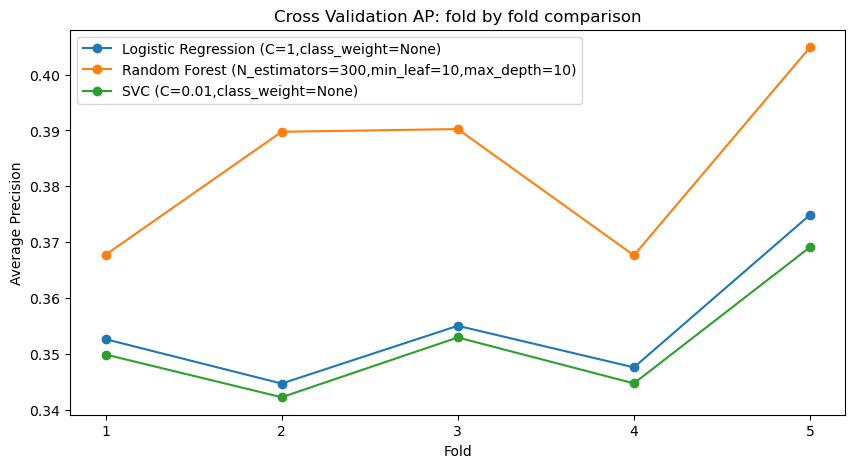

In [35]:
# Hyperparameter tuning

# logistic
p_logistic_grid = {
    "model__C":[0.01, 0.1, 1, 10, 100],
    #DA RIMETTERE, SOLO PER VELOCIZZARE
    #"model__C":[0.01, 0.1],
    "model__class_weight": [None, "balanced"]
}

logistic_grid = GridSearchCV(
    estimator = logistic_pipeline,
    param_grid = p_logistic_grid,
    scoring = "average_precision",
    cv = cv,
    n_jobs = -1,
    return_train_score = True
)

logistic_grid.fit(X_train, y_train)

logistic_mean = logistic_grid.best_score_
logistic_std = logistic_grid.cv_results_["std_test_score"][logistic_grid.best_index_]

# print("=" * 50)
# print("Best Logistic parameters:")
# print(logistic_grid.best_params_)
# print(f"Best logistic cv AP: {logistic_mean} +- {logistic_std}")



# Random Forest
p_randFor_grid = {
    "model__n_estimators": [100, 300],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_leaf": [1, 5, 10],
    "model__class_weight": [None, "balanced"]
}
    #DA RIMETTERE< SOLO PER VELOCIZZARE
    #"model__max_depth": [None],
    #"model__min_samples_leaf": [1, 5],
    #"model__class_weight": [None]}

randFor_grid = GridSearchCV(
    estimator = randFor_pipeline,
    param_grid = p_randFor_grid,
    scoring = "average_precision",
    cv = cv,
    n_jobs = -1,
    return_train_score = True
)

randFor_grid.fit(X_train, y_train)

randFor_mean = randFor_grid.best_score_
randFor_std = randFor_grid.cv_results_["std_test_score"][randFor_grid.best_index_]

# print("=" * 50)
# print("Best Random Forest parameters:")
# print(randFor_grid.best_params_)
# print(f"Best Random Forsest cv AP: {randFor_mean} +- {randFor_std}")



#SVC
p_svm_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

svm_grid = GridSearchCV(
    estimator = svm_pipeline,
    param_grid = p_svm_grid,
    scoring = "average_precision",
    cv = cv,
    n_jobs = -1,
    return_train_score = True
)

svm_grid.fit(X_train, y_train)

svm_mean = svm_grid.best_score_
svm_std = svm_grid.cv_results_["std_test_score"][svm_grid.best_index_]

# print("=" * 50)
# print("Best SVC parameters:")
# print(svm_grid.best_params_)
# print(f"Best SVC cv AP: {svm_mean} +- {svm_std}")


tuning_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Best parameters": logistic_grid.best_params_,
        "CV AP mean": logistic_mean,
        "CV AP std": logistic_std
    },
    {
        "Model": "Random Forest",
        "Best parameters":randFor_grid.best_params_,
        "CV AP mean": randFor_mean,
        "CV AP std": randFor_std
    },
    {
        "Model": "Linear SVC",
        "Best parameters": svm_grid.best_params_,
        "CV AP mean": svm_mean,
        "CV AP std": svm_std
    }
])

display(tuning_results)



logistic_fold_scores = [logistic_grid.cv_results_[f"split{i}_test_score"][logistic_grid.best_index_]
    for i in range(cv.n_splits)]

randFor_fold_scores = [randFor_grid.cv_results_[f"split{i}_test_score"][randFor_grid.best_index_]
    for i in range(cv.n_splits)]

svm_fold_scores = [svm_grid.cv_results_[f"split{i}_test_score"][svm_grid.best_index_]
    for i in range(cv.n_splits)]

fold_comp = pd.DataFrame({
    "Fold" : np.arange(1, cv.n_splits + 1),
    "Logistic AP" : logistic_fold_scores,
    "Random Forest AP" : randFor_fold_scores,
    "SVC AP": svm_fold_scores
})

#fold_comp["diff(RF-L)"] = fold_comp["Random Forest AP"] - fold_comp["Logistic AP"]
display(fold_comp)

# Plot fold comparison

log_label = (f"Logistic Regression "
    f"(C={logistic_grid.best_params_['model__C']},"  
    f"class_weight={logistic_grid.best_params_['model__class_weight']})"
)

randFor_label = (f"Random Forest "
    f"(N_estimators={randFor_grid.best_params_['model__n_estimators']},"
    f"min_leaf={randFor_grid.best_params_['model__min_samples_leaf']},"
    f"max_depth={randFor_grid.best_params_['model__max_depth']})"
)

svm_label = (f"SVC "
    f"(C={svm_grid.best_params_['model__C']},"  
    f"class_weight={svm_grid.best_params_['model__class_weight']})"
)

fig, ax = plt.subplots(figsize = (10,5))
ax.plot(
    fold_comp["Fold"],
    fold_comp["Logistic AP"],
    marker = "o",
    label = log_label
)

ax.plot(
    fold_comp["Fold"],
    fold_comp["Random Forest AP"],
    marker = "o",
    label = randFor_label
)

ax.plot(
    fold_comp["Fold"],
    fold_comp["SVC AP"],
    marker = "o",
    label = svm_label
)

ax.set_xlabel("Fold")
ax.set_ylabel("Average Precision")
ax.set_title("Cross Validation AP: fold by fold comparison")
ax.set_xticks(fold_comp["Fold"])
ax.legend()
plt.show()


## Overfitting Analysis
Per verificare se la Random Forest iniziale soffrisse di overfitting, si e' comparata la Average Precision su training e validation tra gli stessi 5-fold stratificati.

La Random Forest iniziale raggiunge un'AP sul training quasi perfetta (0.9999), ma sul validation diminuisce a (0.3219). Ne risulta un gap di 0.6780. Cio' rappresenta una forte evidenza di overfitting.

Dopo il tuning degli iperparametri, l'AP sul training diminuisce a 0.4479 mentre quella sul validation aumenta a 0.3841. Di conseguenza il gap diminuisce in modo sostanziale a 0.0638.

Questo miglioramento e' coerente con la forte regolarizzazione introdotta limitando la massima profondita' degli alberi (*max_depth=10*) e richiedendo un minimo di 10 osservazioni per foglia (*min_samples_leaf=10*).

Pertanto la configurazione tuned sacrifica le performance sul training a favore di una miglior generalizzazione, riducendo notevolmente l'overfitting e migliorando le performance sul validation.

---
---

In [36]:
# Overfitting Analysis:

# Initial Random Forest:
randFor_initial_cv = cross_validate(randFor_pipeline, X_train, y_train,
    cv = cv, scoring = "average_precision", return_train_score = True, n_jobs = -1)

# Tuned Random Forest:
best_index = randFor_grid.best_index_
grid_results = randFor_grid.cv_results_

comparison = pd.DataFrame({
    "Model": ["Initial RF", "Tuned RF"],
    "Train AP": [randFor_initial_cv["train_score"].mean(),
                grid_results["mean_train_score"][best_index]],
    "Validation AP": [randFor_initial_cv["test_score"].mean(),
                grid_results["mean_test_score"][best_index]],
})

comparison["Generalization gap"] = comparison["Train AP"] - comparison["Validation AP"]
display(comparison)


,Model,Train AP,Validation AP,Generalization gap
0,Initial RF,0.999895,0.321889,0.678006
1,Tuned RF,0.447910,0.384067,0.063843


## Feature Selection

Dopo il tuning degli iperparametri viene valutato se sia possibile ridurre la dimensionalita' del problema selezionando solo alcune delle features presenti, mantenendo una performance comparabile.

La feature selection viene effettuata anch'essa effettuata all'interno della pipeline.

Vengono considerate due strategie differenti:
1. [L1-based feature selection](https://scikit-learn.org/stable/modules/feature_selection.html) per la Logistic Regression.
2. [Tree-based feature selection](https://scikit-learn.org/stable/modules/feature_selection.html) per la Random Forest.

---

#### Logistic Regression: L1-based selection
Per la Logistic Regression viene utilizzato [SelectFromModel](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectFromModel.html) su Logistic Regression con penalizzazione $L^1$.

Dopo il preprocessing vengono generate $35$ features. La selezione $L^1$ ne mantiene $27$ (*).
La performance passa da $\text{AP} = 0.3550 \pm 0.0106$ a $\text{AP} = 0.3545 \pm 0.0105$.
La differenza risulta trascurabile rispetto alla variabilita' osservata nei fold. La feature selection permette pertanto di ridurre il numero di features di circa il $23\%$ senza una significativa perdita di performance.

---

#### Random Forest: Tree-based selection
Poiche' Random Forest e' il modello con la migliore AP dopo il tuning, viene effettuato un esperimento di feature selection anche su di esso.

[SelectFromModel](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectFromModel.html) utilizza in questo caso la feature importance della Random Fores.

Vengono confrontate tre soglie di selezione:
- mediana
- media
- $1.25 \times \text{media}$

con l'obiettivo di trovare il miglior compromesso tra riduzione della dimensionalita' e perdita delle performance. I risultati sono i seguenti
- No Selection: Features selezionate = 35 (*), CV-AP = $0.3841 \pm 0.0144$
- Median: Features selezionate = 18, CV-AP = $0.3826 \pm 0.0148$
- Mean: Features selezionate = 10, CV-AP = $0.3762 \pm 0.0126$
- $1.25 \times \text{mean}$: Features selezionate = 9, CV-AP = $0.3718 \pm 0.0106$

La soglia **median** produce il compromesso migliore, riducendo del circa $49\%$ il numero di feature con una diminuzione dell'AP di soli $0.0015$.
Con soglie piu aggressive la dimensionalita' viene ulteriormente ridotta ma la perdita di performance diventa piu sostanziosa.


(*): *Il numero di feature selezionate riportato si riferisce al fit dei selettori sull'intero training set. Durante la cross validation, la selezione viene ripetuta indipendentemente in ciascun fold e l'insieme delle feature selezionate puo variare*

---

### Conclusioni
La Feature Selection non migliora la performance predittiva rispetto ai modelli che utilizzano tutte le features.

Tuttavia, entrambi gli esperimenti mostrano che una parte considerevole delle features puo' essere eliminata mantenendo prestazioni comparabili.

Per Logistic Regression la selezione $L^1$ riduce la dimensionalita' da 35 a 27 features mantenendo una AP praticamente invariata.

Per Random Forest, la soglia median e' il compromesso migliore, riducendo la dimensionalita' da 35 a 18 feature con una perdita contenuta di AP.

Poiche' il dataset trasformato contiene comunque un numero relativamente ridotto di features e il modello Random Forest completo mantiene la migliore AP, la feature selection non viene utilizzata nel modello predittivo finale.

---
---

In [37]:
# Feature Selection

# L1-based selection for Logistic Regression
feat_selector = SelectFromModel(LogisticRegression(penalty = "l1", solver="liblinear", C = 1,
    random_state = random_seed))

logistic_fs_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("feature_selection", feat_selector),
    ("model", LogisticRegression(max_iter = 2000, C = 1, random_state = random_seed))
])

feat_selection_scores = cross_validate(logistic_fs_pipeline, X_train, y_train,
    cv = cv, scoring = scoring, n_jobs = -1)

#vedo le feature selezionate
logistic_fs_pipeline.fit(X_train, y_train)
logistic_feat_names = logistic_fs_pipeline.named_steps["preprocessor"].get_feature_names_out()
logistic_mask = logistic_fs_pipeline.named_steps["feature_selection"].get_support()
logistic_sel_feat = logistic_feat_names[logistic_mask]

print("=" * 60)
print("Logistic Regression - L1 Feature Selection")
print("=" * 60)
print(f"Number of initial features:{len(logistic_feat_names)}, number of selected features:{len(logistic_sel_feat)}")
print("\nSelected features - Logistic Regression: ")
for feature in logistic_sel_feat:
    print(feature)

print("\nCross-Validation results:")
print(cv_results("Logistic + l1 feature selection", feat_selection_scores))



# Tree-based selection for Random Forest

randFor_thresholds = ["median", "mean", "1.25*mean"]
randFor_fs_results = []
randFor_selected_feature_dict = {}

for threshold in randFor_thresholds:
    randFor_selector =  SelectFromModel(
        RandomForestClassifier(n_estimators= 300, max_depth = 10, min_samples_leaf = 10, class_weight
            = None, random_state = random_seed, n_jobs = -1),
        threshold = threshold
    )

    randFor_fs_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("feature_selection", randFor_selector),
        ("model", RandomForestClassifier(n_estimators= 300, max_depth = 10, min_samples_leaf = 10, class_weight
            = None, random_state = random_seed, n_jobs = -1))
    ])

    randFor_fs_scores = cross_validate(randFor_fs_pipeline, X_train, y_train,
        cv = cv, scoring = scoring, n_jobs = -1)

    # Visualizzo le feature selezionate
    randFor_fs_pipeline.fit(X_train, y_train)
    randFor_feature_names = randFor_fs_pipeline.named_steps["preprocessor"].get_feature_names_out()
    randFor_mask = randFor_fs_pipeline.named_steps["feature_selection"].get_support()
    randFor_selected_features = randFor_feature_names[randFor_mask]
    randFor_selected_feature_dict[threshold] = randFor_selected_features

    # Risultati
    result = cv_results(f"RF selection - {threshold}", randFor_fs_scores)
    randFor_fs_results.append({
        "Threshold": threshold,
        "Initial features": len(randFor_feature_names),
        "Selected features": len(randFor_selected_features),
        "Accuracy": result["Accuracy"],
        "Precision": result["Precision"],
        "Recall": result["Recall"],
        "F1": result["F1"],
        "ROC-AUC": result["ROC-AUC"],
        "Average Precision": result["Average Precision"],
        "AP std": result["AP std"]
    })


randFor_fs_results_df = pd.DataFrame(randFor_fs_results)

print("=" * 60)
print("Random Forest - Feature Selection Comparison")
print("=" * 60)

display(randFor_fs_results_df)


best_randFor_threshold = "median"
print("Selected features - Random Forest median threshold")
for feature in randFor_selected_feature_dict[best_randFor_threshold]:
    print(feature)








Logistic Regression - L1 Feature Selection
Number of initial features:35, number of selected features:27

Selected features - Logistic Regression: 
num__age
num__balance
num__pdays
num__previous
num__prev_cont
num__log_campaign
cat__job_admin.
cat__job_blue-collar
cat__job_entrepreneur
cat__job_housemaid
cat__job_management
cat__job_retired
cat__job_self-employed
cat__job_services
cat__job_student
cat__job_unemployed
cat__job_unknown
cat__marital_divorced
cat__marital_married
cat__education_primary
cat__education_tertiary
cat__education_unknown
cat__default_yes
cat__housing_yes
cat__loan_yes
cat__poutcome_failure
cat__poutcome_success

Cross-Validation results:
{'Model': 'Logistic + l1 feature selection', 'Accuracy': np.float64(0.8924740349091943), 'Precision': np.float64(0.6662439778034897), 'Recall': np.float64(0.16213754008724995), 'F1': np.float64(0.2606571434688495), 'ROC-AUC': np.float64(0.7194392747609756), 'Average Precision': np.float64(0.354520972404414), 'AP std': np.float64

,Threshold,Initial features,Selected features,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,AP std
0,median,35,18,0.893525,0.682867,0.167809,0.269255,0.737755,0.382552,0.014822
1,mean,35,10,0.893552,0.684806,0.167100,0.268487,0.727030,0.376235,0.012585
2,1.25*mean,35,9,0.893248,0.678763,0.166155,0.266817,0.723512,0.371802,0.010574


Selected features - Random Forest median threshold
num__age
num__balance
num__pdays
num__previous
num__prev_cont
num__log_campaign
cat__job_blue-collar
cat__job_retired
cat__job_student
cat__marital_married
cat__marital_single
cat__housing_no
cat__housing_yes
cat__loan_no
cat__poutcome_failure
cat__poutcome_other
cat__poutcome_success
cat__poutcome_unknown


## Feature Extraction

Per la feature extraction utilizziamo PCA con la Logistic Regression. La scelta di usare la Logistic Regression e non il Random Forest e' dovuta a questi fattori:
- Gli alberi decisionali costruiscono degli split lungo gli assi originali: $x_i < c$ mentre PCA costruisce una nuova rappresentazione attraverso componenti della forma $z_k = w^t_k x$. Pertanto una struttura che era facilmente rappresentabile con split sulle feature originali potrebbe diventare meno naturale dopo la PCA, perdendo inoltre parte dell'interpretabilita' della Random Forest.
- Per la Logistic Regression usare PCA e' un esperimento piu' naturale in quanto il modello stesso e' lineare e le componenti principali sono anch'esse combinazioni lineari delle feature originali.

E' importante notare che queste osservazioni sono soltanto delle euristiche. 

Inoltre PCA e' una tecnica unsupervised: le componenti principali vengono costruite considerando solamente la varianza delle feature (X), senza utilizzare il target (Y). Pertanto preservare una percentuale di varianza non garantisce necessariamente di preservare la stessa quantita' di informazioni predittive.

---

### Metodologia

Sono stati effettuati in totale 6 esperimenti. Le prime due grandi classi si differenziano per lo scaling delle features:
- Classe 1: La pipeline e': 
    * Numerical features -> Standard Scaler
    * Categorical Features -> OneHot Encoder
    * PCA: No, 90%, 95%
    * Modello: Logistic Regression Tuned

Questa pipeline pero' presenta un possibile "problema" per la PCA: gran parte della varianza si concentra nelle features numeriche standardizzate $Var(X_i) \approx 1$ mentre le dummy essendo di Bernoulli hanno $Var(X_i) \leq 0.25$ e potenzialmente molto piu' piccola, e questo ci porta alla seconda classe.

- Classe 2: La pipeline e;
    * Numerical Features -> nulla
    * Categorical Features -> Onehot Encoder
    * All Features -> Standard Scaler
    * PCA: No, 90%, 95%
    * Modello: Logistic Regression Tuned

Ora tutte le features hanno $Var(X_i) \approx 1$.

E' importante notare come questa non sia la scelta corretta in assoluto, bensi' una scelta di rappresentazione. Infatti standardizzare anche le variabili dummy ha una conseguenza: categorie rare posso essere amplificate parecchio.

---

### Analisi dei risultati

I risultati sono molto interessanti, partiamo con analizza gli esperimenti della classe 1:
- PCA 90%: Si nota una significativa riduzione della dimensionalita', circa del 66%, passando da 35 featurs a 12 componenti principali. Ma la performance del modello cala drasticamente, circa del 20% e la varianza aumenta leggermente
- PCA 95%: Anche qui abbiamo una riduzione significativa, seppur minore, della dimensionalita', circa del 54%, passando da 35 features a 16 componenti principali. Anche qui si presenta un calo drastico delle performance di circa il 20% con un aumento della varianza.

Passiamo ora agli esperimenti condotti sulla classe 2:
- Iniziamo notando un leggero calo sulle performance della logistic regression. La differenza media e' trascurabile rispetto alla variabilita' osservata nei fold, pertanto non possiamo concludere che il modello abbia performance peggiori:
- PCA 90%: Qui abbiamo il primo risultato veramente interessante. A dispetto di una significativa riduzione della dimensionalita', circa del 40% passando da 35 feat a 21 pc, le performance sembrano rimanere invariate rispetto al modello di riferimento. La varianza e' leggeremente piu alta.
- PCA 95%: Il confronto piu' interesante qui e' con la PCA al 90%. Infatti i due modelli qui sembrano comparabili, mentre la PCA al 95% richiede 2 pc in piu'.

---

### Conclusioni

Il grande calo di performance osservato negli esperimenti della classe 1 suggerisce che la PCA, applicata a features con scale differenti tra variabili numeriche e dummy, possa scartare direzioni rilevanti al fine della classificazione. Dopo la standardizzazione di tutte le feature, si nota che PCA riesce a ridurre sostanzialmente la dimensionalita' mantenendo le performance predittive. Non emerge tuttavia un miglioramento predittivo dovuto alla PCA. PCA90% riduce la rappresentazione da 35 a 21 componenti mantenendo una AP comparabile, mentre PCA95% richiede 23 componenti senza un beneficio evidente. Poiche' la dimensionalita' originale e' gia' contenuto e PCA riduce l'interpretabilita, viene mantenuta la rappresentazione originale nel modello finale.

---
---

,Model,AP mean,AP std,Dimension,Explained Variance
0,Logistic(tuned) - Original,0.355006,0.010597,35,NaN
1,Logistic(tuned) - Original + PCA 90%,0.283883,0.013251,12,0.910282
2,Logistic(tuned) - Original + PCA 95%,0.284940,0.012438,16,0.957717
3,Logistic(tuned) - Scaled,0.354815,0.010614,35,NaN
4,Logistic(tuned) - Scaled + PCA 90%,0.355736,0.012017,21,0.906829
5,Logistic(tuned) - Scaled + PCA 95%,0.355574,0.012171,23,0.951526


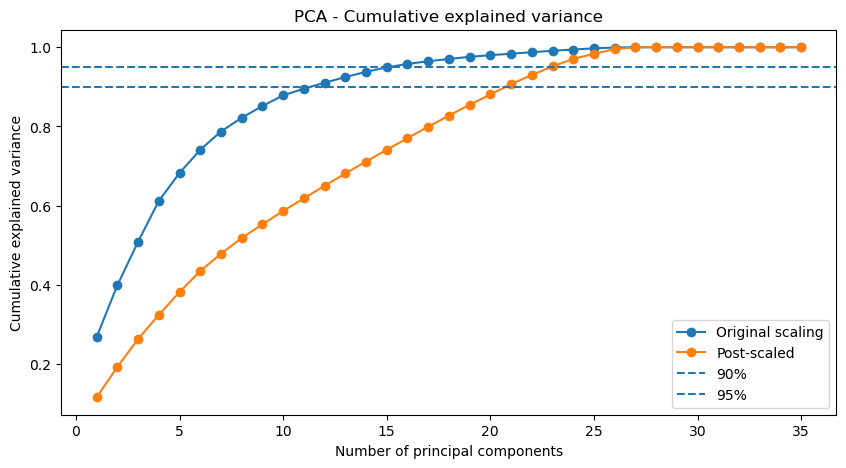

In [38]:
#Feature Extraction

pca_scoring = {"average_precision": "average_precision"}

#Preprocessing without post scaling
cat_pca_pipeline = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown = "ignore", sparse_output = False))
])

num_pca_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

preprocessor_pca = ColumnTransformer([
    ("num", num_pca_pipeline, num_feat),
    ("cat", cat_pca_pipeline, cat_feat)
])

#Preprocessing with post scaling
preprocessor_pca_post = ColumnTransformer([
    ("num", "passthrough", num_feat),
    ("cat", OneHotEncoder(handle_unknown = "ignore", sparse_output = False), cat_feat)
])

#Without post scaling
log_no_pca_pipeline = Pipeline([
    ("preprocessor", preprocessor_pca),
    ("model", LogisticRegression(C = 1, class_weight = None, max_iter = 2000, random_state = random_seed))
])

pca95_pipeline = Pipeline([
    ("preprocessor", preprocessor_pca),
    ("pca", PCA(n_components = 0.95, svd_solver = "full")),
    ("model", LogisticRegression(C = 1, max_iter = 2000, random_state = random_seed))
])

pca90_pipeline = Pipeline([
    ("preprocessor", preprocessor_pca),
    ("pca", PCA(n_components = 0.90, svd_solver = "full")),
    ("model", LogisticRegression(C = 1, max_iter = 2000, random_state = random_seed))
])



#With post scaling
log_no_pca_pipeline_post = Pipeline([
    ("preprocessor", preprocessor_pca_post),
    ("post_scaler", StandardScaler()),
    ("model", LogisticRegression(C = 1, class_weight = None, max_iter = 2000, random_state = random_seed))
])

pca95_pipeline_post = Pipeline([
    ("preprocessor", preprocessor_pca_post),
    #,
    ("post_scaler", StandardScaler()),
    ("pca", PCA(n_components = 0.95, svd_solver = "full")),
    ("model", LogisticRegression(C = 1, max_iter = 2000, random_state = random_seed))
])

pca90_pipeline_post = Pipeline([
    ("preprocessor", preprocessor_pca_post),
    #
    ("post_scaler", StandardScaler()),
    ("pca", PCA(n_components = 0.90, svd_solver = "full")),
    ("model", LogisticRegression(C = 1, max_iter = 2000, random_state = random_seed))
])


models = {
    "Logistic(tuned) - Original": log_no_pca_pipeline,
    "Logistic(tuned) - Original + PCA 90%": pca90_pipeline,
    "Logistic(tuned) - Original + PCA 95%": pca95_pipeline,
    "Logistic(tuned) - Scaled": log_no_pca_pipeline_post,
    "Logistic(tuned) - Scaled + PCA 90%": pca90_pipeline_post,
    "Logistic(tuned) - Scaled + PCA 95%": pca95_pipeline_post,
}

cv_pca_results = {}

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv = cv, scoring = pca_scoring, n_jobs = -1
    )
    cv_pca_results[name] = scores


preprocessor_pca.fit(X_train)
n_initial_feat = len(preprocessor_pca.get_feature_names_out())

preprocessor_pca_post.fit(X_train)
n_post_feat = len(preprocessor_pca_post.get_feature_names_out())



#fit
log_no_pca_pipeline.fit(X_train, y_train)
pca95_pipeline.fit(X_train, y_train)
pca90_pipeline.fit(X_train, y_train)

log_no_pca_pipeline_post.fit(X_train, y_train)
pca90_pipeline_post.fit(X_train, y_train)
pca95_pipeline_post.fit(X_train, y_train)

rows = []
for name in cv_pca_results:
    if "pca" in models[name].named_steps:
        pca = models[name].named_steps["pca"]
        n_components = pca.n_components_
        explained_variance = pca.explained_variance_ratio_.sum()
    else:
        if name == "Logistic(tuned) - Original":
            n_components = n_initial_feat
        elif name == "Logistic(tuned) - Scaled":
            n_components = n_post_feat
        explained_variance = np.nan
    rows.append({
        "Model": name,
        "AP mean": cv_pca_results[name]["test_average_precision"].mean(),
        "AP std": cv_pca_results[name]["test_average_precision"].std(),
        "Dimension": n_components,
        "Explained Variance": explained_variance
    })

pca_results = pd.DataFrame(rows)
display(pca_results)




#PLOT
full_pca_pipeline = Pipeline([
    ("preprocessor", preprocessor_pca),
    ("pca", PCA(svd_solver = "full"))
])
full_pca_pipeline.fit(X_train, y_train)
pca = full_pca_pipeline.named_steps["pca"]
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)


full_pca_pipeline_post = Pipeline([
    ("preprocessor", preprocessor_pca_post),
    ("post_scaler", StandardScaler()),
    ("pca", PCA(svd_solver = "full"))
])
full_pca_pipeline_post.fit(X_train, y_train)
pca_post = full_pca_pipeline_post.named_steps['pca']
cumulative_variance_post = np.cumsum(pca_post.explained_variance_ratio_)

plt.figure(figsize = (10,5))
plt.plot(np.arange(1, len(cumulative_variance)+1), cumulative_variance,
        marker = "o", label = "Original scaling")
plt.plot(np.arange(1, len(cumulative_variance_post)+1), cumulative_variance_post,
        marker = "o", label = "Post-scaled")
plt.axhline(0.90, linestyle = "--", label = "90%")
plt.axhline(0.95, linestyle = "--", label = "95%")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA - Cumulative explained variance")
plt.legend()
plt.show()


## Experiment with duration

In questa sezione viene analizzato l'effettio  dell'introduzione di una feature predittiva, ma non disponibile al momento della previsione date le ipotesi operative.

In particolare si e' aggiunta alle feature numeriche **duration** che gia nella EDA si era mostrata particolarmente predittiva. La sola aggiunta di tale feature ha portato la Logistic Regression da una $\text{AP} \approx 0.3550 \pm 0.0106$ a $\text{AP} \approx 0.5200 \pm 0.0190$

---
---

In [39]:
# Esperimento con il campo duration

#unavailable_feature_dur = ["contact", "day", "month"]
#X_train_dur = train_df.drop(columns = unavailable_feature_dur + ["y"]).copy()
#X_train_dur["prev_cont"] = (X_train_dur["pdays"] != -1).astype(int)
#X_train_dur["log_campaign"] = np.log(X_train_dur["campaign"])
X_train_dur = X_train.copy()
X_train_dur["duration"] = train_df.loc[X_train_dur.index, "duration"]
num_feat_dur = num_feat + ["duration"]

preprocessor_dur = ColumnTransformer([
    ("num", num_pipeline, num_feat_dur),
    ("cat", cat_pipeline, cat_feat)
])

logistic_dur_pipeline = Pipeline([
    ("preprocessor", preprocessor_dur),
    ("model", LogisticRegression(max_iter = 2000, C = 1 , random_state = random_seed))
])

duration_scores = cross_validate(logistic_dur_pipeline, X_train_dur, y_train,
    cv = cv, scoring = scoring, n_jobs = -1)

#print("Logistic with duration")
#print(cv_results("Logistic regression with duration", duration_scores))

display(pd.DataFrame([cv_results("Logistic Regression + duration", duration_scores)]))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,AP std
0,Logistic Regression + duration,0.900465,0.653102,0.317895,0.427564,0.884424,0.519912,0.018976


## Threshold tuning

Fino ad ora, la selezione del modello e il tuning degli iperparametri sono stati effettuati utilizzando la **Average precision (AP)** come metrica primaria. La metrica AP valuta quanto bene il modello riesce a posizionare gli esempi positivi ai primi posti del ranking, sintetizzando il comportamento di Precision e Recall al variare della soglia decisionale.

Pero' per la classificazione finale, abbiamo bisogno di scegliere una soglia decisionale.
Indicando con $p(x) = \mathbb{P}( y = 1 | x)$ la vera probabilita' condizionata, il modello fornisce una sua stima, che indichiamo con:
$$
    \hat p(x)
$$
che viene utilizzata come score per la classe positiva.

la classe predetta e':
$$
 \hat{y} =
    \begin{cases}
    1 & \text{se }\; \hat p(x) \geq \tau\\
    0 & \text{altrimenti}
    \end{cases}
$$

dove $\tau$ e' la soglia decisionale.

Piuttosto che utilizzare la soglia di default ($\tau = 0.5$), la soglia e' selezionata esplicitamente. Siccome il dataset e' sbilanciato e non abbiamo informazioni sul costo dei falsi positivi e falsi negativi, si e' scelto di ottimizzare la soglia in modo tale da massimizzare lo **score F1**. Cosi' facendo otteniamo un bilanciamento tra Precision e Recall.

---

### Metodologia
La soglia non puo essere selezionata utilizzando il test set poiche' questo introdurrebbe informazioni sulla valutazione finale del modello durante il processo di sviluppo. Pertanto sono state generate delle **out-of-fold (OOF) predictions** sul training set utilizzando la Tuned Random Forest e lo stesso schema di 5-fold Stratified Cross-Validation usato negli esperimenti precedenti.

In questo modo, per ogni osservazione (i) si produce uno score $\hat p_i^{\text{OOF}}$ attraverso un modello che non e' stato allenato su tale osservazione. Per ogni possibile soglia ($\tau$), gli score vengono trasformati in predizioni binarie attraverso
$$
    \hat{y}_i^{\tau} = \mathbb{1} \left (\hat p_i^{\text{OOF}} \geq \tau \right )
$$


Per ogni possibile soglia, vengono calcolati Precision, Recall e F1-score.
La soglia selezionata e' quella che massimizza l'OOF F1-score.
$$
    \tau^* = \arg\max_{\tau} F_1(\tau)
$$

---

## Risultati
La soglia ottimale ottenuta nelle out-of-fold prediction e' $\tau^* \approx 0.1913$.
Per tale soglia i valori ottenuti sono:
- Precision = $0.4103$
- Recall = $0.4077$
- F1-score = $0.4090$

---
---

Best Threshold: 0.1912575920609562
OOF Precision : 0.4103235014272122
OOF Recall    : 0.40770503427085797
OOF F1        : 0.40901007700987013


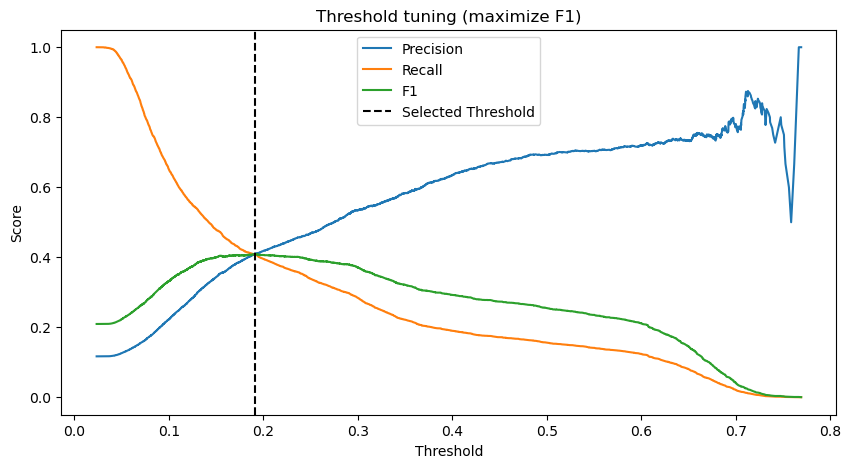

In [40]:
# Threshold tuning
best_model = randFor_grid.best_estimator_
#threshold = 0.5

oof_prob = cross_val_predict(best_model, X_train, y_train, cv = cv,
    method = "predict_proba", n_jobs = -1)[:, 1]

precision_val, recall_val, thresholds = precision_recall_curve(y_train, oof_prob)
f1_val = 2 * precision_val[: -1] * recall_val[: -1] / (precision_val[:-1] + recall_val[:-1] + 1e-10)

best_thr_index = np.argmax(f1_val)
best_threshold = thresholds[best_thr_index]

print("Best Threshold:", best_threshold)
print("OOF Precision :", precision_val[best_thr_index])
print("OOF Recall    :", recall_val[best_thr_index])
print("OOF F1        :", f1_val[best_thr_index])


fig, ax = plt.subplots(figsize = (10, 5))
ax.plot(thresholds, precision_val[:-1], label="Precision")
ax.plot(thresholds, recall_val[:-1], label="Recall")
ax.plot(thresholds, f1_val, label="F1")
ax.axvline(best_threshold, linestyle = "--", color = "black", label = "Selected Threshold")
ax.set_xlabel("Threshold")
ax.set_ylabel("Score")
ax.set_title("Threshold tuning (maximize F1)")
ax.legend()
plt.show()

threshold = best_threshold

## Final evaluation on Test Set
Dopo aver completato la sezione del modello, il tuning degli iperparametri e la scelta della soglia decisionale utilizzando esclusivamente il training set, la configurazione finale viene valutata sul **test set**, che non e' stato utilizzato per selezionate il modello, gli iperparametri o la soglia decisionale.

Il modello selezionato e' il tuned Random Forest, mentre per trasformare le probabilita' predette in classi viene utilizzata la soglia $\tau^* \approx 0.1913$

---

### Risultati
Sul test set si ottengono i seguenti risultati:
- Accuracy: $0.8644$
- Precision: $0.4200$
- Recall: $0.4168$
- F1-score: $0.4184$
- ROC-AUC: $0.7497$
- Average Precision: $0.3909$

La metrica principale rimane la AP. Durante la cross-validation sul training set, la stessa Random Forest aveva ottenuto $\text{AP} \approx 0.3841$

I due valori sono molto vicini, questo indica che la performance osservata durante la cross-validation e' coerente con quella ottenuta sul campione di  test indipendente e non mostra un deterioramento delle capacita' di generalizzazione.

E' inoltre interessante confrontare le metriche dipendenti dalla soglia con quelle ottenute durante il threshold tuning:

Sulle OOF abbiamo ottenuto:
- Precision = $0.4103$
- Recall = $0.4077$
- F1-score = $0.4090$

Anche in questo caso i risultati sono simili, suggerendo che la soglia scelta mediante predizioni OOF si comporta in modo stabile anche su dati non utilizzati durante lo sviluppo.

---

### Confusion Matrix
La confusion matrix ottenuta sul test set e'

$$
\begin{array}{c|cc}
& \hat y=0 & \hat y=1 \\
\hline
y=0 & 7376 & 609\\
y=1 & 617 & 441 
\end{array}
$$

La presenza di un numero consistente sia di falsi positivi che di falsi negativi riflette il compromesso introdotto dalla soglia decisionale selezionata massimizzando l'F1-score. La soglia piu' basse rispetto al valore di default (0.5) permette al modello di identificare un numero maggiore di clienti positivi, accettando pero' un aumento dei falsi positivi.

L'Accuracy, pari a circa 86.4% e' inferiore a quella ottenibile predicendo sempre la classe maggioritaria. Questo non rappresenta una contraddizione: l'accuracy non e' stata selezionata come criterio di ottimizzazione poiche' il dataset e' fortemente sbilanciato. La soglia e' stata invece selezionata per ottenere un compromesso tra Precision e Recall sulla classe positiva.

---

### Conclusioni
Nel complesso, la vicinanza tra le performance ottenute in cross-validation e quelle osservate sul test suggeriscono che il modello selezionato mantenga una capacita predittiva comparabile su campioni non visti precedentemente.

---
---

Accuracy : 0.864425522503594
Precision: 0.42
Recall   : 0.4168241965973535
F1       : 0.41840607210626185
ROC-AUC  : 0.7496686248909522
Average Precision   : 0.39094882292451666


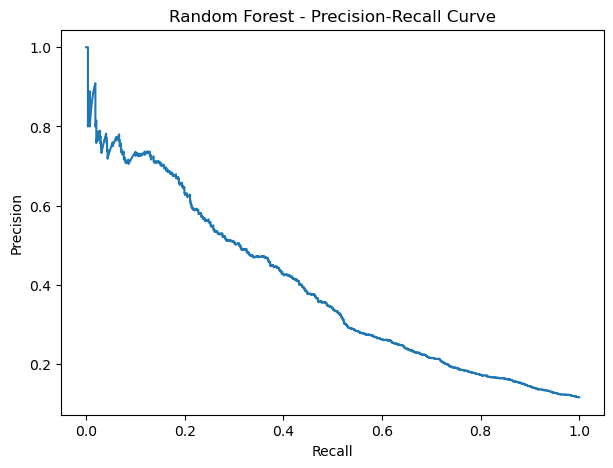

In [41]:
# Valutazione finale del modello sul test set
# Il miglior modello e' gia stato fittato sul training attraverso GridSearchCV

y_test_proba = best_model.predict_proba(X_test)[:, 1]

#Average Precision
ap = average_precision_score(y_test, y_test_proba)

#ROC-AUC
roc_auc = roc_auc_score(y_test, y_test_proba)

#ACCURACY, PRECISION, RECALL, F1
y_test_pred = (y_test_proba >= threshold).astype(int)

accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)

print(f"Accuracy : {accuracy}")
print(f"Precision: {precision}")
print(f"Recall   : {recall}")
print(f"F1       : {f1}")
print(f"ROC-AUC  : {roc_auc}")
print(f"Average Precision   : {ap}")

#Precision-Recall curve
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_test_proba)
plt.figure(figsize=(7,5))
plt.plot(recall_curve, precision_curve)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest - Precision-Recall Curve")
plt.show()


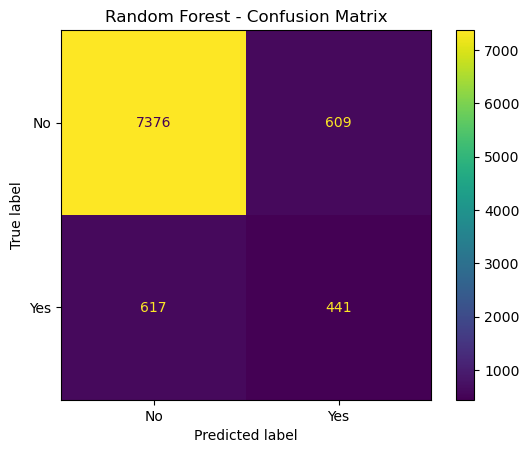

Classification Report
              precision    recall  f1-score   support

           0       0.92      0.92      0.92      7985
           1       0.42      0.42      0.42      1058

    accuracy                           0.86      9043
   macro avg       0.67      0.67      0.67      9043
weighted avg       0.86      0.86      0.86      9043



In [42]:
conf_mat = confusion_matrix(y_test, y_test_pred)
ConfusionMatrixDisplay(confusion_matrix = conf_mat, display_labels=["No", "Yes"]).plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

print("Classification Report")
print(classification_report(y_test, y_test_pred))

## Error Analysis

In questa sezione si cerca di comprendere quali osservazioni vengano classificate erroneamente e se esistano dei pattern sistematici in tali errori.

Per tale motivo, dopo la valutazione finale sul test viene effettuata una analisi dei:
- True Positives (TP)
- True Negatives (TN)
- False Positives (FP)
- False Negatives (FN)

L'analisi viene condotta esclusivamente con finalita' diagnostiche. Poiche' utilizza il test set, i risultati ottenuti non vengono impiegati per modificare il modello.

---

### Overall error analysis
Utilizzando la soglia decisionale precedentemente selezionata, $\tau^* \approx 0.1913$ la Random Forest produce sul test set
$$
TP = 441, \qquad TN = 7376, \qquad FP = 609, \qquad FN = 617
$$
Sono quindi presenti (1058) osservazioni realmente positive e (7985) realmente negative.

Il Recall complessivo e': $\frac{441}{1058} \approx 41.68\%$.

Il False Negative Rate e': $FNR = \frac{FN}{TP + FN} \approx 58.32\%$.

Il False Positive Rate e': $FPR = \frac{FP}{TN + FP} \approx 7.63\%$.

Il modello commette pertanto errori molto differenti sulle due classi: identifica correttamente circa il (41.7%) dei clienti che sottoscrivono effettivamente il deposito, mentre solo il (7.6%) dei veri negativi viene erroneamente classificato come positivo.
Tale comportamento e' legato sia allo sbilanciamento del problema sia alla scelta della soglia decisionale.

---

### Numerical Features
Per le features numeriche vengono confrontate media e mediana nei gruppi TP, FN, TN e FP. I confronti piu interessanti sono:
- $TP\; \text{vs}\; FN$: per studiare la differenze tra i clienti positivi corretamente identificati e quelli non.
- $TN\; \text{vs}\; FP$: per studiare le caratteristiche che portano il modello ad assegnare erroneamente una previsione positiva.

Le differenze piu' importanti emergono dalle features relative alla storia delle campagne precedenti.

Ad esempio:
- Il numero di contatti precedenti (**previous**) e' circa (2.36) tra i True Positive, ma solo (0.32) tra i False Negative.
- Analogamente, **prev_cont**, la feature che indica se il cliente ha ricevuto contatti precedenti, ha valore (1) per circa il (72.3%) dei True Positives, ma solamente per circa il (13.3%) dei False Negative.
- Anche **pdays** mostra tale differenza, ma la sua interpretazione richiede piu' cautela poiche' contiene il valore speciale (-1) che rappresenta l'assenza di un precedente contatt e non una quantita' numerica pura.
- Per **log_campaign** si osserva invece un valore medio piu' basso nei True Positive (0.43) rispetto ai False Negative (0.60). Cio' suggerisce che un numero elevato di contatti effettuati durante la campagna corrente e' maggiormente presente tra i positivi non identificati correttamente.

E' importante notare che tali osservazioni sono puramente descrittive e non implicano relazioni causali.

---

### Error rates across subgroups
Si e' studiato il tasso di errore per ogni gruppo, in quanto la sola composizione degli errori in tali gruppi poteva essere fuorviante: ad esempio osservare che una categoria rappresenta una grande percentuale di False Negative potrebbe essere semplicemente una conseguenza della sua elevata frequenza nel dataset.

Per tale motivo vengono calcolati i tassi di errore condizionati all'appartenenza a ciascun sottogruppo.

Per un gruppo (g), il False Positive Rate e':
$$
FPR_g = \frac{FP_g}{TN_g + FP_g}
$$
mentre il False Negative Rate e':
$$
FNR_g = \frac{FN_g}{TP_g + FN_g}
$$
e il Recall del gruppo e' 
$$
Recall_g = 1-FNR_g
$$
Insieme a tali metriche viene considerato anche il **support** del gruppo in quanto valori estremi su pochi esempi vanno interpretati con piu' cautela.

---

#### Previous campaign information

Il pattern piu' evidente riguarda la disponibilita' di informazioni relative alle campagne precedenti:
- Per i clienti che non erano stati precedentemente contattati (prev_cont = 0) si ha: 
$$
Recall \approx 18.57\%, \qquad FNR \approx 81.43\%
$$
- Per i clienti con almeno un contatto (prev_cont = 1) si ottiene invece:
$$
Recall \approx 79.55\%, \qquad FNR \approx 20.45\%
$$

La capacita' del modello di riconoscere un cliente positivo e' molto maggiore quando e' disponibile una storia di contatti precedenti.

Lo stesso fenomeno emerge in modo ancora piu' evidente considerando **poutcome** ovvero l'esito della precedente campagna:
- Per poutcome = unknown si ha 
$$
Recall \approx 18.57\%, \qquad FNR \approx 81.43\%
$$
- Per poutcome = success il modello presenta un Recall del (100%): tutti i (199) clienti realmente positivi appartenenti a tale gruppo vengono classificati come positivi. Tuttavia, lo stesso gruppo presenta anche un FPR del (100%): tutti i (107) clienti realmente negativi vengono anch'essi classificati come positivi

Questo mostra che un precedente successo rappresenta un segnale estremamente forte per il modello. La Random Forest, alla soglia decisionale selezionata, tende praticamente ad assegnare la classe positiva a tutti i clienti che hanno sottoscritto il deposito in passato.

---

#### Housing and personal loan

Emergono differenze rilevanti anche considerando la presenza di mutuo e di un prestito personale.
- Per i clienti con housing = yes otteniamo;
$$
Recall \approx 16.62\%, \qquad FNR \approx 83.38\%
$$
- Per i clienti con housing = no otteniamo:
$$
Recall \approx 55.67\%, \qquad FNR \approx 44.33\%
$$

Il modello tende a perdere clienti positivi appartenenti al gruppo con mutuo.

Un comportamento analogo emerge per loan:
- Per i clienti con loan = yes otteniamo;
$$
Recall \approx 13.64\%, \qquad FNR \approx 86.36\%
$$
- Per i clienti con loan = no otteniamo:
$$
Recall \approx 44.23\%, \qquad FNR \approx 55.77\%
$$

Tali pattern sono coerenti con le osservazioni effettuate nella EDA, dove housing=yes e loan=yes erano associati a una minore frequenza di sottoscrizione. Questi gruppi sono associati pertanto a score mediamente meno favorevoli alla classe positiva.

---

#### Job categories

Anche la feature Job mostra differenze considerevoli nei tassi di errore.
- I gruppi **student** e **retired** mostrano Recall particolarmente elevata:
$$
    Recall_{\text{student}} \approx 84\%, 
    \qquad
    Recall_{\text{retired}} \approx 78\%
$$
Tuttavia questi gruppi mostrano anche un FPR elevato:
$$
    FPR_{\text{student}} \approx 61.54\%, 
    \qquad
    FPR_{\text{retired}} \approx 34.38\%
$$
Il modello tende pertanto ad assegnare frequentemente la classe positiva a queste categorie, cio' permette di individuare buona parte dei veri positivi, ma produce numerosi falsi positivi.
- Per i gruppi **blue-collar** e **entrepreneur**, la situazione e' opposta:
$$
    Recall_{\text{blue\_collar}} \approx 24.09\%, 
    \qquad
    Recall_{\text{entrepreneur}} \approx 9.09\%
$$
Per entrepreneur pero' tale risultato va interpretato con cautela in quanto sono presenti solo (22) esempi positivi appartenenti a tale categoria.

---

#### Distribution of predicted scores

Per analizzare ulteriormente gli errori si considera anche la distribuzione delle probabilita' stimate dal modello.

Per gli esempi realmente positivi vengono confrontate le probabilita' assegnate ai True Positive e ai False Negative, mentre per gli esempi realmente negativi vengono confrontati True Negative e False Positive.

La soglia $\tau^* \approx 0.1913$ separa le due classi predette.

Tale analisi permette di distinguere gli errori borderline, per la quale la probabilita' stimata e' vicina alla soglia decisionale e il modello e' pertanto incerto, dagli errori nei quali il modello assegna score molto distante dalla soglia decisionale e per cui il modello e' molto confidente.

---

#### Confident errors

Vengono analizzati separatamente i False Positive con probabilita' piu alta (molto confidente) e i False Negative con probabilita piu' bassa (molto confidente).
- Tra i False Positive piu' confidenti emerge un pattern evidente: tutte le dieci osservazioni con score piu' elevato presentano:
$$
    \text{poutcome} = \text{succes}, 
    \qquad \text{prev\_cont} = 1, 
    \qquad \text{housing} = \text{no},
    \qquad \text{loan} = \text{no}
$$
I dieci false positive con score maggiore ricevono valori compresi tra ($\approx 0.69$ e $\approx 0.72$), molto lontani dalla soglia di ($\approx 0.19$). Tali casi confermano pertanto che un precedente esito positivo della campagna e l'assenza di mutui e prestiti personali, rappresentano un segnale forte per la Random Forest che e' associato all'assegnazione di score elevati anche ad acluni clienti che, nel test set, non sottoscrivono il deposito.
- Tra i False Negative piu' confidenti emerge un pattern differente: Quasi tutti i casi con score piu' basso hanno:
$$
    \text{poutcome} = \text{unknown}, 
    \qquad \text{prev\_cont} = 0, 
    \qquad \text{housing} = \text{yes},
    \qquad \text{job} = \text{blue\_collar}
$$
Questi ricevono uno score inferiore a (0.05), molto inferiore alla soglia, nonostante appartengano realmente alla classe positiva.

---

### Conclusioni
L'analisi degli errori mostra come essi non sono distribuiti uniformemente tra le diverse tipologie di cliente.

Il pattern piu' significativo riguarda le informazioni relative alle campagne precedenti. Quando e' disponibile una storia dei contatti precedenti, e in particolare quando il precedente esito e' positivo, il modello tende fortemente a predire la classe positiva, ovvero che il cliente sottoscrivera' il deposito. Cio' aumenta notevolmente la Recall tra questi clienti, ma puo' produrre contemporaneamente un numero elevato di falsi positivi.

Al contrario, in assenza di una storia precedente, il modello incontra maggiori difficolta' nell'individuare i clienti che sottoscriveranno il deposito. Cio' suggerisce che, per tali clienti le informazioni disponibili prima del contatto potrebbero non essere sufficienti a separare efficacemente le due classi.

Anche la presenza di mutui o prestiti personali e alcune categorie lavorative sono associate a differenze importanti nel comportamento del modello.

Questi risultati evidenziano il compromesso introdotto dalla soglia decisionale: categorie per le quali il modello assegna solitamente score elevati possono mostrare contemporaneamente un Recall elevato e un FPR alto, mentre gruppi ai quali vengono assegnati score bassi mostrano un comportamento opposto.

Tale analisi e' stata effettuata sul test set e pertanto le osservazioni emerse non vengono utilizzate per modificare il modello, ma solo per descrivere e interpretare i limiti di quest'ultimo.

---
---

In [43]:
# Error Analysis

err_df = X_test.copy()
err_df["y"] = y_test.to_numpy()
err_df["y_pred"] = y_test_pred
err_df["y_proba"] = y_test_proba
err_df["threshold_distance"] = np.abs(err_df["y_proba"] - threshold)

true_pos = err_df[(err_df["y"] == 1) & (err_df["y_pred"] == 1)].copy()
true_neg = err_df[(err_df["y"] == 0) & (err_df["y_pred"] == 0)].copy()
false_pos = err_df[(err_df["y"] == 0) & (err_df["y_pred"] == 1)].copy()
false_neg = err_df[(err_df["y"] == 1) & (err_df["y_pred"] == 0)].copy()


print("Error-Analysis dataframe created.")
print(f"Total observation: {len(err_df)}")

Error-Analysis dataframe created.
Total observation: 9043


In [44]:
n_tp = len(true_pos)
n_tn = len(true_neg)
n_fp = len(false_pos)
n_fn = len(false_neg)

n_positive = n_tp + n_fn
n_negative = n_tn + n_fp

# false pos e neg rate
overall_fnr = n_fn / n_positive
overall_fpr = n_fp / n_negative

# Recall
overall_recall = n_tp / n_positive

print("=" * 50)
print("Overall error analysis")
print("=" * 50)

print(f"True Positives : {n_tp}")
print(f"True Negatives : {n_tn}")
print(f"False Positives: {n_fp}")
print(f"False Negatives: {n_fn}")

print("\n")

print(f"Positive support: {n_positive}")
print(f"Negative support: {n_negative}")

print("\n")

print(f"Recall / TPR: {overall_recall:.4f}")
print(f"FNR         : {overall_fnr:.4f}")
print(f"FPR         : {overall_fpr:.4f}")

Overall error analysis
True Positives : 441
True Negatives : 7376
False Positives: 609
False Negatives: 617


Positive support: 1058
Negative support: 7985


Recall / TPR: 0.4168
FNR         : 0.5832
FPR         : 0.0763


In [45]:
# Costruisco tabella con media, mediana delle feature num nei gruppi.
def num_err_summary(features):
    rows = []
    for feature in features:
        rows.append({
            "feature": feature,
            "TP_mean": true_pos[feature].mean(),
            "FN_mean": false_neg[feature].mean(),
            "TP_median": true_pos[feature].median(),
            "FN_median": false_neg[feature].median(),

            "TN_mean": true_neg[feature].mean(),
            "FP_mean": false_pos[feature].mean(),
            "TN_median": true_neg[feature].median(),
            "FP_median": false_pos[feature].median(),
        })
    return pd.DataFrame(rows)

num_error_summary = num_err_summary(num_feat)
display(num_error_summary.round(3))



,feature,TP_mean,FN_mean,TP_median,FN_median,TN_mean,FP_mean,TN_median,FP_median
0,age,43.751,40.566,37.0,39.000,40.836,43.049,39.000,37.0
1,balance,1889.782,1570.953,935.0,556.000,1224.871,2241.695,383.000,889.0
2,pdays,132.723,28.661,98.0,-1.000,29.519,116.637,-1.000,92.0
3,previous,2.363,0.323,2.0,0.000,0.379,1.900,0.000,1.0
4,prev_cont,0.723,0.133,1.0,0.000,0.121,0.619,0.000,1.0
5,log_campaign,0.431,0.600,0.0,0.693,0.749,0.498,0.693,0.0


In [46]:
# Tasso di errore per sottogruppo
def group_error_rates(df, feature):
    rows = []
    for value, group in df.groupby(feature, dropna=False):
        tp = ((group["y"] == 1) & (group["y_pred"] == 1)).sum()
        fn = ((group["y"] == 1) & (group["y_pred"] == 0)).sum()
        tn = ((group["y"] == 0) & (group["y_pred"] == 0)).sum()
        fp = ((group["y"] == 0) & (group["y_pred"] == 1)).sum()

        positive_support = tp + fn
        negative_support = tn + fp

        recall = tp / positive_support if positive_support > 0 else np.nan
        fnr = fn / positive_support if positive_support > 0 else np.nan
        fpr = fp / negative_support if negative_support > 0 else np.nan

        rows.append({
            feature: value,
            "support": len(group),
            "positive_support": positive_support,
            "negative_support": negative_support,
            "TP": tp,
            "FN": fn,
            "Recall": recall,
            "FNR": fnr,
            "TN": tn,
            "FP": fp,
            "FPR": fpr
        })
    result = pd.DataFrame(rows)
    result = result.sort_values("support", ascending = False)
    return result.reset_index(drop = True)

error_group_features = ["prev_cont", "poutcome", "housing", "loan", "job"]

for feature in error_group_features:
    print("\n")
    print("=" * 50)
    print(f"ERROR RATES BY: {feature}")
    print("=" * 50)

    result = group_error_rates(err_df, feature)
    result_display = result.copy()
    result_display["Recall"] *= 100
    result_display["FNR"] *= 100
    result_display["FPR"] *= 100

    display(result_display.round(2))








ERROR RATES BY: prev_cont


,prev_cont,support,positive_support,negative_support,TP,FN,Recall,FNR,TN,FP,FPR
0,0,7370,657,6713,122,535,18.57,81.43,6481,232,3.46
1,1,1673,401,1272,319,82,79.55,20.45,895,377,29.64




ERROR RATES BY: poutcome


,poutcome,support,positive_support,negative_support,TP,FN,Recall,FNR,TN,FP,FPR
0,unknown,7370,657,6713,122,535,18.57,81.43,6481,232,3.46
1,failure,1012,140,872,79,61,56.43,43.57,679,193,22.13
2,other,355,62,293,41,21,66.13,33.87,216,77,26.28
3,success,306,199,107,199,0,100.00,0.00,0,107,100.00




ERROR RATES BY: housing


,housing,support,positive_support,negative_support,TP,FN,Recall,FNR,TN,FP,FPR
0,yes,4948,379,4569,63,316,16.62,83.38,4499,70,1.53
1,no,4095,679,3416,378,301,55.67,44.33,2877,539,15.78




ERROR RATES BY: loan


,loan,support,positive_support,negative_support,TP,FN,Recall,FNR,TN,FP,FPR
0,no,7612,970,6642,429,541,44.23,55.77,6052,590,8.88
1,yes,1431,88,1343,12,76,13.64,86.36,1324,19,1.41




ERROR RATES BY: job


,job,support,positive_support,negative_support,TP,FN,Recall,FNR,TN,FP,FPR
0,management,1947,260,1687,104,156,40.00,60.00,1560,127,7.53
1,blue-collar,1902,137,1765,33,104,24.09,75.91,1732,33,1.87
2,technician,1529,177,1352,67,110,37.85,62.15,1263,89,6.58
3,admin.,1030,122,908,39,83,31.97,68.03,847,61,6.72
4,services,806,71,735,22,49,30.99,69.01,711,24,3.27
5,retired,452,100,352,78,22,78.00,22.00,231,121,34.38
6,self-employed,336,45,291,22,23,48.89,51.11,265,26,8.93
7,entrepreneur,301,22,279,2,20,9.09,90.91,273,6,2.15
8,unemployed,279,44,235,20,24,45.45,54.55,213,22,9.36
9,housemaid,227,24,203,10,14,41.67,58.33,188,15,7.39


In [47]:
# Composizione degli errori per feature
def err_group_composition(feature):
    return pd.DataFrame({
        "True Positive (%)": true_pos[feature].value_counts(normalize = True) * 100,
        "False Negative (%)": false_neg[feature].value_counts(normalize = True) * 100,
        "True Negative (%)": true_neg[feature].value_counts(normalize = True) * 100,
        "False Positive (%)": false_pos[feature].value_counts(normalize = True) * 100,
    }).round(2)

for feature in error_group_features:
    print("\n")
    print("=" * 50)
    print(f"ERROR COMPOSITION BY: {feature}")
    print("=" * 50)

    display(err_group_composition(feature))



ERROR COMPOSITION BY: prev_cont


,True Positive (%),False Negative (%),True Negative (%),False Positive (%)
prev_cont,,,,
0,27.66,86.71,87.87,38.1
1,72.34,13.29,12.13,61.9




ERROR COMPOSITION BY: poutcome


,True Positive (%),False Negative (%),True Negative (%),False Positive (%)
poutcome,,,,
failure,17.91,9.89,9.21,31.69
other,9.30,3.40,2.93,12.64
success,45.12,NaN,NaN,17.57
unknown,27.66,86.71,87.87,38.10




ERROR COMPOSITION BY: housing


,True Positive (%),False Negative (%),True Negative (%),False Positive (%)
housing,,,,
no,85.71,48.78,39.0,88.51
yes,14.29,51.22,61.0,11.49




ERROR COMPOSITION BY: loan


,True Positive (%),False Negative (%),True Negative (%),False Positive (%)
loan,,,,
no,97.28,87.68,82.05,96.88
yes,2.72,12.32,17.95,3.12




ERROR COMPOSITION BY: job


,True Positive (%),False Negative (%),True Negative (%),False Positive (%)
job,,,,
admin.,8.84,13.45,11.48,10.02
blue-collar,7.48,16.86,23.48,5.42
entrepreneur,0.45,3.24,3.70,0.99
housemaid,2.27,2.27,2.55,2.46
management,23.58,25.28,21.15,20.85
retired,17.69,3.57,3.13,19.87
self-employed,4.99,3.73,3.59,4.27
services,4.99,7.94,9.64,3.94
student,9.52,1.30,0.68,13.14


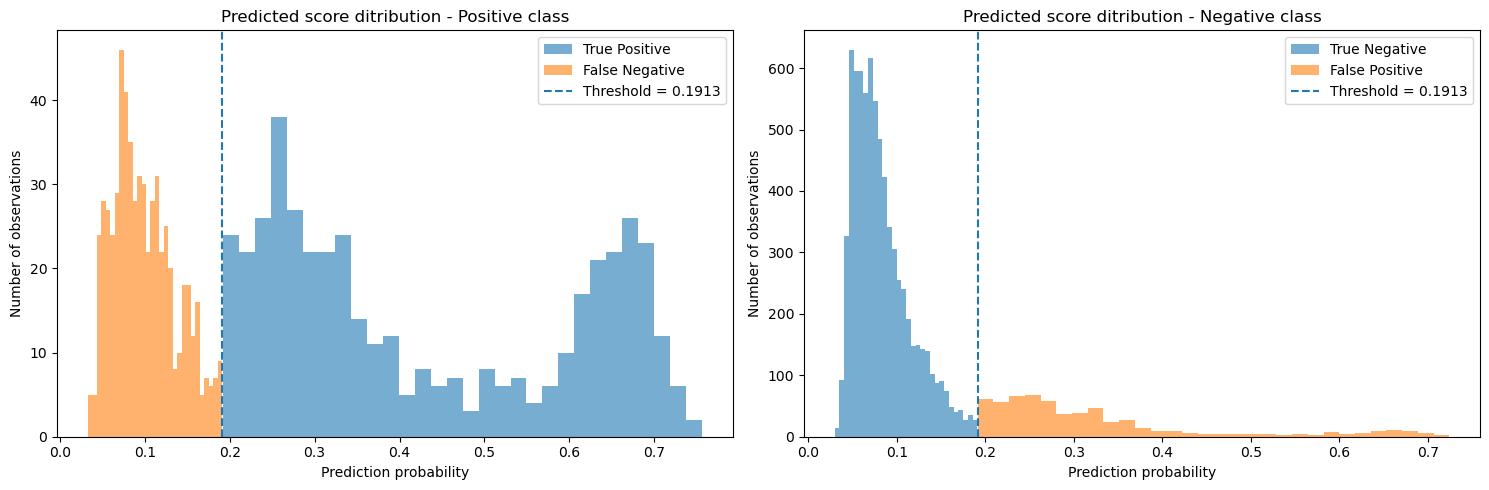

In [48]:
# Distribuzione dei punteggi
fig, axes = plt.subplots(1, 2, figsize = (15,5))

#score positivi
axes[0].hist(true_pos["y_proba"], bins = 30, alpha = 0.6, label = "True Positive")
axes[0].hist(false_neg["y_proba"], bins = 30, alpha = 0.6, label = "False Negative")
axes[0].axvline(threshold, linestyle = "--", label = f"Threshold = {threshold:.4f}")
axes[0].set_xlabel("Prediction probability")
axes[0].set_ylabel("Number of observations")
axes[0].set_title("Predicted score ditribution - Positive class")
axes[0].legend()

#score negativi
axes[1].hist(true_neg["y_proba"], bins = 30, alpha = 0.6, label = "True Negative")
axes[1].hist(false_pos["y_proba"], bins = 30, alpha = 0.6, label = "False Positive")
axes[1].axvline(threshold, linestyle = "--", label = f"Threshold = {threshold:.4f}")
axes[1].set_xlabel("Prediction probability")
axes[1].set_ylabel("Number of observations")
axes[1].set_title("Predicted score ditribution - Negative class")
axes[1].legend()

plt.tight_layout()
plt.show()

In [49]:
# Confident errors

# Falsi positivi  (y_prob alta => modello molto convinto)
confident_fp = false_pos.sort_values("y_proba", ascending = False)

# Falsi negativi (y_prob bassa => modello molto convinto)
confident_fn = false_neg.sort_values("y_proba", ascending = True)

err_features = ["age", "job", "marital", "education", "balance", "housing", "loan",
    "pdays", "previous", "poutcome", "prev_cont", "log_campaign", "y_proba", "threshold_distance"]

print("=" * 50)
print("MOST CONFIDENT FALSE POSITIVES")
print("=" * 50)

display(confident_fp[err_features].head(10))



print("=" * 50)
print("MOST CONFIDENT FALSE NEGATIVES")
print("=" * 50)

display(confident_fn[err_features].head(10))

MOST CONFIDENT FALSE POSITIVES


,age,job,marital,education,balance,housing,loan,pdays,previous,poutcome,prev_cont,log_campaign,y_proba,threshold_distance
43423,80,retired,married,secondary,8304,no,no,118,11,success,1,0.000000,0.724396,0.533139
44200,60,services,single,secondary,739,no,no,182,1,success,1,0.000000,0.715761,0.524503
42383,25,student,single,secondary,304,no,no,188,2,success,1,0.000000,0.701861,0.510603
43135,25,student,single,secondary,469,no,no,187,2,success,1,0.000000,0.701172,0.509915
42709,76,retired,married,tertiary,2991,no,no,95,2,success,1,0.000000,0.700051,0.508793
42753,69,retired,divorced,secondary,4572,no,no,92,3,success,1,0.693147,0.695601,0.504344
43896,83,retired,married,tertiary,4761,no,no,93,1,success,1,0.693147,0.694993,0.503736
42599,27,services,single,secondary,302,no,no,189,1,success,1,0.000000,0.690970,0.499713
44777,62,admin.,married,secondary,4608,no,no,186,1,success,1,0.000000,0.686012,0.494754
44678,60,admin.,married,secondary,12980,no,no,182,1,success,1,0.693147,0.685693,0.494435


MOST CONFIDENT FALSE NEGATIVES


,age,job,marital,education,balance,housing,loan,pdays,previous,poutcome,prev_cont,log_campaign,y_proba,threshold_distance
18072,44,housemaid,married,primary,-156,no,yes,-1,0,unknown,0,0.693147,0.032721,0.158537
38725,35,blue-collar,married,secondary,205,yes,yes,312,1,failure,1,1.945910,0.034702,0.156555
12684,49,blue-collar,married,primary,-157,yes,no,-1,0,unknown,0,1.098612,0.035672,0.155586
37017,50,blue-collar,married,primary,-522,yes,no,-1,0,unknown,0,1.098612,0.037690,0.153568
14871,56,blue-collar,married,primary,0,yes,no,-1,0,unknown,0,0.000000,0.037983,0.153274
36599,37,blue-collar,married,primary,-106,yes,yes,-1,0,unknown,0,0.000000,0.040269,0.150989
38534,51,blue-collar,married,primary,129,yes,no,-1,0,unknown,0,0.693147,0.040947,0.150310
36985,40,blue-collar,married,unknown,87,yes,no,-1,0,unknown,0,1.098612,0.042593,0.148664
34273,36,blue-collar,married,secondary,218,yes,no,-1,0,unknown,0,1.791759,0.042925,0.148333
37328,52,services,married,primary,306,yes,no,-1,0,unknown,0,1.609438,0.043057,0.148200


## Limitations and Conclusions

---

### Conclusions

L'obiettivo del progetto e' stato sviluppare un sistema di classificazione binaria in grado di **prioritizzare i clienti con maggiore propensione alla sottoscrizione di un deposito a termine**, utilizzando solamente le informazioni considerate disponibili prima del successivo contatto.

Tale scelta ha avuto un ruolo centrale nel progetto. In particolare, feature relative al contatto corrente come *contact*, *day*, *month* e *duration* sono state escluse dal modello. L'esperimento separato condotto reintroducendo la feature *duration* ha mostrato quanto questa variabile sia predittiva, facendo aumentare l'Average Precision della Logistic Regression da circa 0.3550 a 0.5200.

Tale incremento conferma pero' l'importanza di definire correttamente il **prediction time**: una feature molto informativa non necessariamente e' utilizzabile se non e' disponibile nel momento in cui deve essere effettuata la previsione.

Tra i modelli confrontati la **Random Forest** ha ottenuto le migliori prestazioni in cross-validation. Dopo il tuning il modello finale raggiunge $AP_{CV} \approx 0.3841 \pm 0.0144$
superando Logistic Regression e linear SVM in tutti e cinque i fold.

Gli esperimenti di feature selection hanno mostrato che e' possibile ridurre sensibilmente il numero di features mantenendo prestazioni simili. La selezione basata sulla Random forest riduce le feature da 35 a 18 con una diminuzione molto limitata della Average Precision. Poiche' la dimensionalita' originale del problema e' comunque piuttosto contenuta, la feature selection non viene utilizzata nel modello finale.

Un risultato analogo emerge dalla feature extraction. Dopo una standardizzazione coerente della rappresentazione, la PCA permette di ridurre le 35 feature trasformate a 21 componenti principali mantenendo una Average Precision sostanzialmente invariata. Non emerge tuttavia un miglioramento nelle performance predittive e pertanto, analogamente al caso della feature selection, si e' mantenuta la rappresentazione originale.

Dopo la selezione del modello, la soglia decisionale e' stata ottimizzata separatamente utilizzando delle out-of-fold prediction sul training set. In assenza di informazioni relative ai costi di falsi positivi e falsi negativi, si e' scelto di selezionare la soglia che massimizza lo score F1: $\tau^* \approx 0.1913$.

Applicando il modello finale e tale soglia decisionale al test set si ottengono i seguenti risultati:
$$
    \text{Precision}_{\text{test}} \approx 0.4200
$$
$$
    \text{Recall}_{\text{test}} \approx 0.4168
$$
$$
    \text{F1}_{\text{test}} \approx 0.4184
$$
$$
    \text{AP}_{\text{test}} \approx 0.3909
$$

La vicinanza tra $\text{AP}_{\text{CV}} = 0.3841$ e $\text{AP}_{\text{test}}$ indica che le prestazioni osservate sul test set sono coerenti con quelle stimate in fase di sviluppo e non mostrano un evidente deterioramento della capacita' di generalizzazione.

L'analisi degli errori evidenzia inoltre che essi non sono distribuiti uniformemente. Le informazioni relative alle campagne precedenti come *poutcome* e *prev_cont*, risultano associate a differenze marcate nel comportamento del classificatore. Il modello identifica con maggiore facilita i clienti per i quali e' disponibile una storia precedente informativa, mentre incontra maggiori difficolta' quando tale informazione e' assente.

Nel complesso, i risultati mostrano quindi che e' possibile ottenere un ranking dei clienti nettamente piu' informativo rispetto ad una strategia non predittiva.

---

## Limitations

I risultati ottenuti devono tuttavia essere interpretati tenendo conto di alcuni limiti del progetto.

Per cominciare il dataset rappresenta uno specifico contesto storico e operativo. Le relazioni osservate potrebbero cambiare nel tempo, in presenza di campagne differenti o variazione nella popolazione dei clienti. Il train-test split stratificato utilizzato nel progetto non tiene conto della componente temporale dei dati. Un'applicazione reale futura potrebbe pertanto tener conto di cio' addestrando il modello su campagne precedenti e valutandolo sulle successive.

Il dataset inoltre contiene informazioni riassuntive sulla storia dei contatti con il cliente, come ad esempio il numero dei contatti precedenti (*previous*), il tempo trascorso dall'ultimo contatto (*pdays*) e l'esito della campagna precedente (*poutcome*). Non contenendo una cronologia dettagliata delle singole interazioni, il modello puo' di conseguenza utilizzare tali informazioni aggregate ma non puo' analizzare direttamente l'evoluzione temporale.

La definizione delle feature disponibili dipende fortemente dal **prediction setting** adottato nel progetto. L'esclusione delle feature *contact*, *day*, *month* e *duration* deriva dall'ipotesi di effettuare la previsione prima della programmazione o dell'esecuzione del nuovo contatto. In uno scenario operativo differente, le feature disponibili e pertanto le prestazioni raggiungibili potrebbero cambiare.

Un ulteriore limite riguarda la scelta della soglia decisionale. La soglia $\tau^* \approx 0.1913$ e' stata scelta massimizzando lo score F1, utilizzato come compromesso tra Precision e Recall in assenza di informazioni sui costi dei vari errori. In un'applicazione reale la soglia potrebbe invece essere determinata considerando: il costo di un contatto, il ritorno atteso da una sottoscrizione, il budget disponibile e il costo associato ai falsi positivi e falsi negativi. Di conseguenza la soglia ottenuta non va interpretata come ottimale per ogni task.

Infine, le associazioni individuate nell'EDA e nell'error analysis **non sono di natura causale**. Il fatto che una determinata caratteristica sia associata a una maggiore o minore probabilita' predetta di sottoscrizione non permette di concludere che la modifica di tale caratteristica provocherebbe un cambiamento nella probabilita' di sottoscrizione.

In conclusione, il progetto mostra che la Random Forest sviluppata puo' essere utilizzata come strumento di **prioritizzazione dei clienti**, ma il passaggio a un'applicazione operativa richiederebbe una validazione su dati temporalmente successivi e la definizione di costi e benefici reali di tale campagna. 

---
---